# 1. Imports

In [1]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.0.6
NumPy: 2.5.3


# 2. Load datasets

In [2]:
# Load the three CSV files into Pandas DataFrames
# Each DataFrame will be used for a different part of our analysis

sales = pd.read_csv("../data/sales.csv")          # Transaction/order data
customers = pd.read_csv("../data/customers.csv")  # Customer information
products = pd.read_csv("../data/products.csv")    # Product information

In [3]:
# Check the number of rows and columns in each dataset
# .shape returns (number_of_rows, number_of_columns)

print("Sales:", sales.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Sales: (250000, 21)
Customers: (40000, 15)
Products: (2000, 12)


# 3. Initial inspection

In [4]:
# Display basic information about the Sales dataset
# This shows:
# - Number of rows
# - Column names
# - Data types
# - Number of non-null values

sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 21 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Order_ID            250000 non-null  str    
 1   Customer_ID         250000 non-null  str    
 2   Product_ID          250000 non-null  str    
 3   Order_Date          250000 non-null  str    
 4   Order_Time          250000 non-null  str    
 5   Delivery_Date       250000 non-null  str    
 6   Quantity            250000 non-null  int64  
 7   Unit_Price          250000 non-null  float64
 8   Order_Value         250000 non-null  float64
 9   Shipping_Cost       250000 non-null  float64
 10  Coupon_Code         50185 non-null   str    
 11  Coupon_Discount     250000 non-null  float64
 12  Total_Amount        250000 non-null  float64
 13  Payment_Mode        250000 non-null  str    
 14  Order_Status        250000 non-null  str    
 15  Rating              120030 non-null  float64


In [5]:
# Display basic information about the Customers dataset

customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Customer_ID        40000 non-null  str    
 1   Customer_Name      40000 non-null  str    
 2   Gender             40000 non-null  str    
 3   Age                40000 non-null  int64  
 4   Age_Group          40000 non-null  str    
 5   Date_of_Birth      40000 non-null  str    
 6   Email              40000 non-null  str    
 7   Phone              40000 non-null  str    
 8   City               40000 non-null  str    
 9   State              40000 non-null  str    
 10  Pincode            40000 non-null  int64  
 11  Registration_Date  40000 non-null  str    
 12  Customer_Tier      40000 non-null  str    
 13  Total_Orders       40000 non-null  int64  
 14  Total_Spent        40000 non-null  float64
dtypes: float64(1), int64(3), str(11)
memory usage: 4.6 MB


In [6]:
# Display basic information about the Products dataset

products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Product_ID        2000 non-null   str    
 1   Product_Name      2000 non-null   str    
 2   Category          2000 non-null   str    
 3   Brand             2000 non-null   str    
 4   Original_Price    2000 non-null   float64
 5   Discount_Percent  2000 non-null   int64  
 6   Discount_Amount   2000 non-null   float64
 7   Selling_Price     2000 non-null   float64
 8   Stock_Quantity    2000 non-null   int64  
 9   Weight_kg         2000 non-null   float64
 10  Avg_Rating        2000 non-null   float64
 11  Total_Reviews     2000 non-null   int64  
dtypes: float64(5), int64(3), str(4)
memory usage: 187.6 KB


# 4. Data Understanding

## Check missing values

In [7]:
# Check how many missing values are present in each column
# isna() identifies missing values
# sum() counts the missing values for each column

sales_missing = sales.isna().sum()

# Display only columns that actually contain missing values
sales_missing[sales_missing > 0]

Coupon_Code    199815
Rating         129970
Review_Text    129970
dtype: int64

In [8]:
# Check for missing values in the Customers dataset

customers_missing = customers.isna().sum()

# Display only columns that contain missing values
customers_missing[customers_missing > 0]

Series([], dtype: int64)

In [9]:
# Check for missing values in the Products dataset

products_missing = products.isna().sum()

# Display only columns that contain missing values
products_missing[products_missing > 0]

Series([], dtype: int64)

## Check Duplicate

In [10]:
# Check for completely duplicated rows in each dataset
# duplicated() returns True for rows that are exact duplicates
# sum() counts how many duplicate rows exist

print("Sales duplicates:", sales.duplicated().sum())
print("Customers duplicates:", customers.duplicated().sum())
print("Products duplicates:", products.duplicated().sum())

Sales duplicates: 0
Customers duplicates: 0
Products duplicates: 0


## Check unique ID

In [11]:
# Check how many unique IDs exist in each dataset.
# nunique() counts the number of distinct values in a column.

print("Unique Order IDs:", sales["Order_ID"].nunique())
print("Unique Customer IDs in Sales:", sales["Customer_ID"].nunique())
print("Unique Product IDs in Sales:", sales["Product_ID"].nunique())

print("Unique Customer IDs in Customers:", customers["Customer_ID"].nunique())
print("Unique Product IDs in Products:", products["Product_ID"].nunique())

Unique Order IDs: 250000
Unique Customer IDs in Sales: 39914
Unique Product IDs in Sales: 2000
Unique Customer IDs in Customers: 40000
Unique Product IDs in Products: 2000


## Check relationship with data

In [12]:
# Check whether every Customer_ID in sales.csv
# exists in customers.csv.
#
# isin() checks whether each sales Customer_ID
# exists in the customer master dataset.

customer_match = sales["Customer_ID"].isin(customers["Customer_ID"])

# Count sales records whose Customer_ID is NOT found
# in the customers dataset.

print("Sales records with missing Customer_ID match:", (~customer_match).sum())

Sales records with missing Customer_ID match: 0


In [13]:
# Check whether every Product_ID in sales.csv
# exists in products.csv.

product_match = sales["Product_ID"].isin(products["Product_ID"])

# Count sales records whose Product_ID is NOT found
# in the products dataset.

print("Sales records with missing Product_ID match:", (~product_match).sum())

Sales records with missing Product_ID match: 0


## Understanding of Date Columns

In [14]:
# Check the current data types of the date/time columns.
# We want to know whether Pandas has recognized them
# as actual datetime values or as plain text.

print("Order_Date type:", sales["Order_Date"].dtype)
print("Order_Time type:", sales["Order_Time"].dtype)
print("Delivery_Date type:", sales["Delivery_Date"].dtype)

Order_Date type: str
Order_Time type: str
Delivery_Date type: str


In [15]:
# Display a few examples of the date and time columns.
# This helps us understand the exact format stored in the CSV.

print(sales[["Order_Date", "Order_Time", "Delivery_Date"]].head(10))

   Order_Date Order_Time Delivery_Date
0  2026-06-07   08:20:00    2026-06-10
1  2025-02-04   20:05:00    2025-02-07
2  2026-03-12   14:59:00    2026-03-19
3  2025-01-27   14:33:00    2025-02-02
4  2024-06-30   07:19:00    2024-07-02
5  2025-09-18   11:56:00    2025-09-23
6  2026-03-01   10:32:00    2026-03-05
7  2024-06-19   17:46:00    2024-06-23
8  2025-02-12   12:19:00    2025-02-15
9  2024-10-19   07:45:00    2024-10-25


In [16]:
# Display the earliest and latest order dates as they are currently stored.
# We are only inspecting the raw values at this stage.

print("First order date:", sales["Order_Date"].min())
print("Last order date:", sales["Order_Date"].max())

First order date: 2024-06-01
Last order date: 2026-06-30


### Convert date into datetimes

In [17]:
# Convert the date columns from strings to Pandas datetime objects.
# This allows us to perform date calculations and extract
# useful time-based features later.

sales["Order_Date"] = pd.to_datetime(sales["Order_Date"])
sales["Delivery_Date"] = pd.to_datetime(sales["Delivery_Date"])

# Convert Order_Time into a time-aware format.
# We keep the date and time separate for now because
# they may be useful independently during analysis.

sales["Order_Time"] = pd.to_datetime(
    sales["Order_Time"],
    format="%H:%M:%S"
).dt.time

In [18]:
# Check the data types after conversion.
# Order_Date and Delivery_Date should now be datetime64.

print("Order_Date type:", sales["Order_Date"].dtype)
print("Order_Time type:", sales["Order_Time"].dtype)
print("Delivery_Date type:", sales["Delivery_Date"].dtype)

Order_Date type: datetime64[us]
Order_Time type: object
Delivery_Date type: datetime64[us]


## Statistical summary

In [19]:
# Generate descriptive statistics for numerical columns in the Sales dataset.
# This gives us:
# - count
# - mean
# - standard deviation
# - minimum
# - 25th percentile
# - median (50th percentile)
# - 75th percentile
# - maximum

sales.describe()

,Order_Date,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Discount,Total_Amount,Rating,Customer_Age
count,250000,250000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,120030.000000,250000.000000
mean,2025-06-15 09:37:10.156799,2025-06-19 21:38:16.512000,1.249580,19202.477645,23967.862192,4.911971,250.001146,23722.773017,4.399400,35.309416
min,2024-06-01 00:00:00,2024-06-03 00:00:00,1.000000,26.130000,26.130000,0.000000,0.000000,-21.560000,3.000000,18.000000
25%,2024-12-08 00:00:00,2024-12-13 00:00:00,1.000000,1551.550000,1825.890000,0.000000,0.000000,1803.900000,4.000000,26.000000
50%,2025-06-15 00:00:00,2025-06-19 00:00:00,1.000000,7208.930000,8411.160000,0.000000,0.000000,8339.490000,4.000000,33.000000
75%,2025-12-22 00:00:00,2025-12-27 00:00:00,1.000000,24433.270000,28612.810000,0.000000,0.000000,28344.920000,5.000000,43.000000
max,2026-06-30 00:00:00,2026-07-07 00:00:00,3.000000,136973.330000,410919.990000,90.000000,41092.000000,410919.990000,5.000000,75.000000
std,NaN,NaN,0.535689,26720.495176,37629.320529,18.141581,1399.928532,37267.644163,0.663915,12.574524


In [20]:
# Generate descriptive statistics for numerical columns
# in the Customers dataset.

customers.describe()

,Age,Pincode,Total_Orders,Total_Spent
count,40000.000000,40000.000000,40000.000000,40000.00000
mean,35.306225,549135.098375,5.003475,118539.15886
std,12.581443,259430.688860,2.232485,106205.42346
min,18.000000,100010.000000,0.000000,0.00000
25%,26.000000,325689.750000,3.000000,37814.14750
50%,33.000000,547573.500000,5.000000,90059.66000
75%,43.000000,773876.000000,6.000000,169958.41750
max,75.000000,999986.000000,17.000000,890131.55000


In [21]:
# Generate descriptive statistics for numerical columns
# in the Products dataset.

products.describe()

,Original_Price,Discount_Percent,Discount_Amount,Selling_Price,Stock_Quantity,Weight_kg,Avg_Rating,Total_Reviews
count,2000.000000,2000.000000,2000.00000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000
mean,18323.619210,27.471000,5143.28014,13180.33907,503.479000,2.640980,4.398185,60.015000
std,29472.155725,13.309874,9732.99126,21514.94963,287.140337,1.373574,0.095983,27.645161
min,52.250000,5.000000,6.29000,26.13000,10.000000,0.210000,3.910000,15.000000
25%,1522.505000,16.000000,332.26000,1088.03750,250.750000,1.430000,4.340000,38.000000
50%,4775.355000,27.000000,1154.91500,3543.41500,504.500000,2.725000,4.400000,54.000000
75%,22358.115000,39.000000,5452.93500,16063.81250,749.000000,3.790000,4.460000,78.000000
max,149658.640000,50.000000,71289.60000,136973.33000,1000.000000,5.000000,4.760000,139.000000


## Columns

In [22]:
# Display the names of all columns in the Sales dataset.
# This helps us identify which columns are categorical,
# numerical, date/time, or identifiers.

print(sales.columns.tolist())

['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date', 'Order_Time', 'Delivery_Date', 'Quantity', 'Unit_Price', 'Order_Value', 'Shipping_Cost', 'Coupon_Code', 'Coupon_Discount', 'Total_Amount', 'Payment_Mode', 'Order_Status', 'Rating', 'Review_Text', 'City', 'State', 'Customer_Age', 'Customer_Age_Group']


In [23]:
# Display the names of all columns in the Customers dataset.

print(customers.columns.tolist())

['Customer_ID', 'Customer_Name', 'Gender', 'Age', 'Age_Group', 'Date_of_Birth', 'Email', 'Phone', 'City', 'State', 'Pincode', 'Registration_Date', 'Customer_Tier', 'Total_Orders', 'Total_Spent']


In [24]:
# Display the names of all columns in the Products dataset.

print(products.columns.tolist())

['Product_ID', 'Product_Name', 'Category', 'Brand', 'Original_Price', 'Discount_Percent', 'Discount_Amount', 'Selling_Price', 'Stock_Quantity', 'Weight_kg', 'Avg_Rating', 'Total_Reviews']


## Check Categorical columns

In [25]:
# Display the unique values and their frequencies
# for important categorical columns in the Sales dataset.
#
# value_counts() tells us how many records belong
# to each category.

print("Payment Mode:")
print(sales["Payment_Mode"].value_counts())

print("\nOrder Status:")
print(sales["Order_Status"].value_counts())

print("\nCustomer Age Group:")
print(sales["Customer_Age_Group"].value_counts())

print("\nState:")
print(sales["State"].value_counts().head(20))

Payment Mode:
Payment_Mode
UPI            128474
COD             82093
Debit Card      28856
Credit Card     10577
Name: count, dtype: int64

Order Status:
Order_Status
Delivered     200139
Cancelled      12507
Returned       12493
Shipped        12459
Processing     12402
Name: count, dtype: int64

Customer Age Group:
Customer_Age_Group
26-35    87847
18-25    61594
36-45    50169
46-55    30359
56-65    15176
65+       4855
Name: count, dtype: int64

State:
State
UP             32631
Haryana        32064
Rajasthan      31666
Maharashtra    25478
Punjab         25235
Gujarat        25171
Tamil Nadu     19792
Delhi          19524
West Bengal    19450
Karnataka      18989
Name: count, dtype: int64


In [26]:
# Check the main categorical columns in the Customers dataset.
# value_counts() shows how many customers belong to each category.

print("Gender:")
print(customers["Gender"].value_counts())

print("\nAge Group:")
print(customers["Age_Group"].value_counts())

print("\nCustomer Tier:")
print(customers["Customer_Tier"].value_counts())

print("\nState:")
print(customers["State"].value_counts().head(20))

Gender:
Gender
male      20003
female    19997
Name: count, dtype: int64

Age Group:
Age_Group
26-35    14059
18-25     9876
36-45     8011
46-55     4841
56-65     2437
65+        776
Name: count, dtype: int64

Customer Tier:
Customer_Tier
Platinum    27349
Gold         6692
Silver       5959
Name: count, dtype: int64

State:
State
UP             5218
Haryana        5124
Rajasthan      5057
Punjab         4083
Maharashtra    4050
Gujarat        4026
Tamil Nadu     3170
West Bengal    3140
Delhi          3116
Karnataka      3016
Name: count, dtype: int64


In [27]:
# Check the main categorical columns in the Products dataset.
#
# value_counts() shows the number of products
# belonging to each category or brand.

print("Category:")
print(products["Category"].value_counts())

print("\nBrand:")
print(products["Brand"].value_counts())

Category:
Category
Electronics    290
Fashion        285
Home           285
Beauty         285
Sports         285
Books          285
Grocery        285
Name: count, dtype: int64

Brand:
Brand
Nike          114
Puma          114
Samsung        58
HP             58
boAt           58
Noise          58
Apple          58
Levis          57
Peter          57
Titan          57
IKEA           57
Prestige       57
Philips        57
Godrej         57
Urban          57
Lakme          57
Mamaearth      57
Nivea          57
Dove           57
Plum           57
Decathlon      57
Yoga           57
Dumbbells      57
Fiction        57
NCERT          57
Comics         57
Notebook       57
Stationery     57
Aashirvaad     57
Fortune        57
Lays           57
Nescafe        57
Haldiram       57
Name: count, dtype: int64


## Validate product pricing logic

In [28]:
# Calculate the expected discount amount using:
# Original Price × Discount Percentage.
#
# Dividing Discount_Percent by 100 converts values such as
# 20 into 0.20.

expected_discount = (
    products["Original_Price"] *
    products["Discount_Percent"] / 100
)

# Calculate the expected selling price:
# Original Price - Discount Amount.

expected_selling_price = (
    products["Original_Price"] -
    products["Discount_Amount"]
)

# Calculate the difference between the dataset's values
# and our calculated values.

discount_difference = (
    products["Discount_Amount"] - expected_discount
)

selling_price_difference = (
    products["Selling_Price"] - expected_selling_price
)

# Display the largest absolute differences.
# A value close to zero means the calculation is consistent.

print(
    "Maximum discount calculation difference:",
    discount_difference.abs().max()
)

print(
    "Maximum selling price calculation difference:",
    selling_price_difference.abs().max()
)

Maximum discount calculation difference: 0.005000000001018634
Maximum selling price calculation difference: 1.4551915228366852e-11


In [29]:
# Calculate the expected Order Value using:
# Quantity × Unit Price

expected_order_value = (
    sales["Quantity"] *
    sales["Unit_Price"]
)

# Calculate the difference between the dataset's
# Order_Value and our calculated value.

order_value_difference = (
    sales["Order_Value"] -
    expected_order_value
)

# Display the largest absolute difference.
# A value extremely close to zero means the relationship
# is mathematically consistent.

print(
    "Maximum Order Value calculation difference:",
    order_value_difference.abs().max()
)

Maximum Order Value calculation difference: 5.820766091346741e-11


## Negative balance check

In [30]:
# Filter the Sales dataset to find orders
# where Total_Amount is negative.

negative_amounts = sales[sales["Total_Amount"] < 0]

# Display how many such records exist.

print("Number of negative Total_Amount records:", len(negative_amounts))

# Display the important columns for these records.
# This will help us understand why the amount is negative.

print(
    negative_amounts[
        [
            "Order_ID",
            "Order_Date",
            "Quantity",
            "Order_Value",
            "Shipping_Cost",
            "Coupon_Discount",
            "Total_Amount",
            "Order_Status",
            "Payment_Mode"
        ]
    ].head(20)
)

Number of negative Total_Amount records: 5
             Order_ID Order_Date  Quantity  Order_Value  Shipping_Cost  \
84204   ORD0000084205 2026-06-26         1        35.57          62.36   
182883  ORD0000182884 2026-01-22         1        26.13          52.31   
207695  ORD0000207696 2026-03-07         1        26.13          62.56   
216234  ORD0000216235 2025-05-19         1        26.13          57.40   
249820  ORD0000249821 2025-03-26         1        35.57          52.45   

        Coupon_Discount  Total_Amount Order_Status Payment_Mode  
84204             100.0         -2.07    Delivered          UPI  
182883            100.0        -21.56    Delivered          COD  
207695            100.0        -11.31    Delivered          UPI  
216234            100.0        -16.47    Delivered          COD  
249820            100.0        -11.98    Cancelled          UPI  


In [31]:
# Check for logically invalid negative or zero values
# in important transaction columns.
#
# These checks help us identify potential data-quality
# problems before starting the cleaning phase.

print("Quantity <= 0:",
      (sales["Quantity"] <= 0).sum())

print("Unit Price <= 0:",
      (sales["Unit_Price"] <= 0).sum())

print("Shipping Cost < 0:",
      (sales["Shipping_Cost"] < 0).sum())

print("Coupon Discount < 0:",
      (sales["Coupon_Discount"] < 0).sum())

print("Total Amount < 0:",
      (sales["Total_Amount"] < 0).sum())

Quantity <= 0: 0
Unit Price <= 0: 0
Shipping Cost < 0: 0
Coupon Discount < 0: 0
Total Amount < 0: 5


## Missing values

In [32]:
# Check whether orders with a missing Coupon_Code
# also have zero Coupon_Discount.
#
# If this relationship is consistent, we can reasonably
# interpret missing Coupon_Code as "no coupon used".

missing_coupon = sales["Coupon_Code"].isna()

print("Orders with missing Coupon_Code:",
      missing_coupon.sum())

print(
    "Missing Coupon_Code + zero Coupon_Discount:",
    (missing_coupon & (sales["Coupon_Discount"] == 0)).sum()
)

print(
    "Missing Coupon_Code + non-zero Coupon_Discount:",
    (missing_coupon & (sales["Coupon_Discount"] != 0)).sum()
)

Orders with missing Coupon_Code: 199815
Missing Coupon_Code + zero Coupon_Discount: 199815
Missing Coupon_Code + non-zero Coupon_Discount: 0


# 5. Data Cleaning

## Create copy

In [33]:
# Create copies of the original datasets.
#
# We will perform all cleaning operations on these copies.
# The original DataFrames remain unchanged, which allows us
# to compare the cleaned data with the original data later.

sales_clean = sales.copy()
customers_clean = customers.copy()
products_clean = products.copy()

print("Clean copies created successfully.")

Clean copies created successfully.


## Handle Coupon_Code

In [34]:
# Replace missing Coupon_Code values with "No Coupon".
#
# We are doing this because our earlier investigation showed
# that every missing Coupon_Code has a Coupon_Discount of zero.
# Therefore, the missing value has a meaningful business interpretation.

sales_clean["Coupon_Code"] = (
    sales_clean["Coupon_Code"].fillna("No Coupon")
)

# Verify that there are no missing Coupon_Code values remaining.

print(
    "Missing Coupon_Code after cleaning:",
    sales_clean["Coupon_Code"].isna().sum()
)

Missing Coupon_Code after cleaning: 0


## Handle Rating and Review_Text

In [35]:
# Replace missing Review_Text values with "No Review".
#
# A missing review indicates that the customer did not
# provide written feedback.

sales_clean["Review_Text"] = (
    sales_clean["Review_Text"].fillna("No Review")
)

# We intentionally keep missing Rating values as NaN.
# This prevents us from inventing ratings for customers
# who did not provide one.

# Check the number of missing values after cleaning.

print(
    "Missing Review_Text:",
    sales_clean["Review_Text"].isna().sum()
)

print(
    "Missing Rating:",
    sales_clean["Rating"].isna().sum()
)

Missing Review_Text: 0
Missing Rating: 129970


## Validate delivery dates

In [36]:
# Calculate the delivery duration for each order.
#
# Subtracting two datetime columns gives a time difference.
# .dt.days converts that difference into the number of days.

sales_clean["Delivery_Days"] = (
    sales_clean["Delivery_Date"] -
    sales_clean["Order_Date"]
).dt.days

# Check whether any order has a negative delivery duration.
# A negative value would mean the order was delivered
# before it was placed, which would be a data-quality issue.

print(
    "Orders with negative delivery days:",
    (sales_clean["Delivery_Days"] < 0).sum()
)

# Display some basic statistics about delivery time.

print("\nDelivery Days Summary:")
print(sales_clean["Delivery_Days"].describe())

Orders with negative delivery days: 0

Delivery Days Summary:
count    250000.000000
mean          4.500768
std           1.710942
min           2.000000
25%           3.000000
50%           5.000000
75%           6.000000
max           7.000000
Name: Delivery_Days, dtype: float64


## Check customer age consistency

In [37]:
# Merge customer age information into the sales dataset temporarily.
#
# We use a temporary DataFrame so that we don't modify
# sales_clean yet.

age_check = sales_clean[
    ["Order_ID", "Customer_ID", "Customer_Age"]
].merge(
    customers_clean[
        ["Customer_ID", "Age"]
    ],
    on="Customer_ID",
    how="left"
)

# Calculate the difference between the age stored in the
# sales transaction and the age stored in the customer master.

age_check["Age_Difference"] = (
    age_check["Customer_Age"] -
    age_check["Age"]
)

# Count records where the two ages are different.

print(
    "Orders with different customer ages:",
    (age_check["Age_Difference"] != 0).sum()
)

# Display the distribution of the age difference.

print("\nAge Difference Summary:")
print(age_check["Age_Difference"].value_counts().sort_index())

Orders with different customer ages: 0

Age Difference Summary:
Age_Difference
0    250000
Name: count, dtype: int64


## Validate age groups

In [38]:
# Create the expected age group from Customer_Age.
#
# pd.cut() places each age into the appropriate age range.
#
# right=False means the intervals are left-inclusive:
# 18 belongs to 18-25
# 26 belongs to 26-35
# 36 belongs to 36-45, etc.

expected_age_group = pd.cut(
    sales_clean["Customer_Age"],
    bins=[18, 26, 36, 46, 56, 66, float("inf")],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"],
    right=False
)

# Compare the calculated age group with the dataset's
# existing Customer_Age_Group.

age_group_mismatch = (
    expected_age_group.astype(str) !=
    sales_clean["Customer_Age_Group"].astype(str)
)

# Count how many records have inconsistent age groups.

print(
    "Age group mismatches:",
    age_group_mismatch.sum()
)

Age group mismatches: 0


## Check Order_Date and Delivery_Date for missing values

In [39]:
# Check whether any Order_Date or Delivery_Date values
# are missing.
#
# Dates are important for our later sales forecasting,
# so we should make sure these fields are complete.

print(
    "Missing Order_Date:",
    sales_clean["Order_Date"].isna().sum()
)

print(
    "Missing Delivery_Date:",
    sales_clean["Delivery_Date"].isna().sum()
)

Missing Order_Date: 0
Missing Delivery_Date: 0


## Validate customer registration dates

In [40]:
# Check the data type of Registration_Date.
# It should ideally be a datetime type.

print("Registration_Date data type:",
      customers_clean["Registration_Date"].dtype)

# Check whether any customer registration dates are missing.

print(
    "Missing Registration_Date:",
    customers_clean["Registration_Date"].isna().sum()
)

Registration_Date data type: str
Missing Registration_Date: 0


In [41]:
# Convert Registration_Date from string to Pandas datetime.
#
# This allows us to perform date calculations later,
# such as calculating how long a customer has been registered.

customers_clean["Registration_Date"] = pd.to_datetime(
    customers_clean["Registration_Date"]
)

# Verify the conversion.

print(
    "Registration_Date data type:",
    customers_clean["Registration_Date"].dtype
)

Registration_Date data type: datetime64[us]


## Check registration date vs order date

In [42]:
# Find the earliest order date for each customer.
#
# groupby() groups all orders belonging to the same customer,
# and min() finds that customer's first order date.

first_order = (
    sales_clean
    .groupby("Customer_ID")["Order_Date"]
    .min()
    .reset_index()
)

# Rename the column to make its meaning clear.

first_order = first_order.rename(
    columns={"Order_Date": "First_Order_Date"}
)

# Merge the customer's registration date with their
# first order date.

registration_check = customers_clean[
    ["Customer_ID", "Registration_Date"]
].merge(
    first_order,
    on="Customer_ID",
    how="left"
)

# Find customers whose first order happened BEFORE
# their registration date.

invalid_registration = registration_check[
    registration_check["First_Order_Date"] <
    registration_check["Registration_Date"]
]

print(
    "Customers whose first order is before registration:",
    len(invalid_registration)
)

Customers whose first order is before registration: 0


## Check Date_of_Birth

In [43]:
# Check whether Date_of_Birth is stored as a proper datetime type.

print(
    "Date_of_Birth data type:",
    customers_clean["Date_of_Birth"].dtype
)

# Convert Date_of_Birth to datetime.
#
# errors="coerce" converts any invalid date into NaT
# instead of causing the notebook to stop.

customers_clean["Date_of_Birth"] = pd.to_datetime(
    customers_clean["Date_of_Birth"],
    errors="coerce"
)

# Check whether any invalid/missing dates were created.

print(
    "Invalid or missing Date_of_Birth:",
    customers_clean["Date_of_Birth"].isna().sum()
)

Date_of_Birth data type: str
Invalid or missing Date_of_Birth: 0


In [44]:
# Calculate the customer's age at the time of registration.
#
# We subtract the birth year from the registration year.
# Then we subtract 1 if the customer's birthday had not
# occurred yet in that registration year.

registration_age = (
    customers_clean["Registration_Date"].dt.year
    - customers_clean["Date_of_Birth"].dt.year
    - (
        (
            customers_clean["Registration_Date"].dt.month
            < customers_clean["Date_of_Birth"].dt.month
        )
        |
        (
            (customers_clean["Registration_Date"].dt.month
             == customers_clean["Date_of_Birth"].dt.month)
            &
            (customers_clean["Registration_Date"].dt.day
             < customers_clean["Date_of_Birth"].dt.day)
        )
    ).astype(int)
)

# Compare the calculated age with the Age column.

age_mismatch = (
    registration_age != customers_clean["Age"]
)

print(
    "Customers with age mismatch:",
    age_mismatch.sum()
)

Customers with age mismatch: 40000


In [45]:
# Use the latest date available in the customer/order data
# as a reference date for calculating age.
#
# We use the latest Order_Date because the dataset contains
# historical transactions.

reference_date = sales_clean["Order_Date"].max()

# Calculate the expected age as of the reference date.

reference_age = (
    reference_date.year
    - customers_clean["Date_of_Birth"].dt.year
    - (
        (
            reference_date.month
            < customers_clean["Date_of_Birth"].dt.month
        )
        |
        (
            (reference_date.month
             == customers_clean["Date_of_Birth"].dt.month)
            &
            (reference_date.day
             < customers_clean["Date_of_Birth"].dt.day)
        )
    ).astype(int)
)

# Compare the calculated age with the Age column.

age_mismatch = (
    reference_age != customers_clean["Age"]
)

print("Reference date:", reference_date)

print(
    "Customers with age mismatch:",
    age_mismatch.sum()
)

Reference date: 2026-06-30 00:00:00
Customers with age mismatch: 40000


In [46]:
# Display a sample of customers with their Age,
# Date_of_Birth, and Registration_Date.
#
# This helps us visually understand why the calculated
# age does not match the Age column.

age_check_sample = customers_clean[
    [
        "Customer_ID",
        "Age",
        "Date_of_Birth",
        "Registration_Date"
    ]
].head(10)

print(age_check_sample)

    Customer_ID  Age Date_of_Birth Registration_Date
0  CUST00000001   48    1977-01-13        2024-01-28
1  CUST00000002   73    1952-01-20        2023-08-25
2  CUST00000003   31    1994-01-09        2023-08-30
3  CUST00000004   41    1984-01-12        2024-03-11
4  CUST00000005   53    1972-01-15        2024-04-19
5  CUST00000006   19    2006-01-06        2024-04-26
6  CUST00000007   34    1991-01-10        2024-05-10
7  CUST00000008   60    1965-01-16        2024-04-02
8  CUST00000009   35    1990-01-10        2023-10-03
9  CUST00000010   42    1983-01-12        2023-11-22


In [47]:
# Calculate the difference between the dataset Age
# and the age calculated from Date_of_Birth.
#
# This tells us whether the mismatch is consistently
# around 1 year, several years, etc.

age_difference = (
    customers_clean["Age"] - reference_age
)

print(age_difference.describe())

print("\nAge difference frequency:")
print(age_difference.value_counts().sort_index().head(20))

count    40000.0
mean        -1.0
std          0.0
min         -1.0
25%         -1.0
50%         -1.0
75%         -1.0
max         -1.0
dtype: float64

Age difference frequency:
-1    40000
Name: count, dtype: int64


## Validate Total_Orders and Total_Spent

In [48]:
# Calculate the actual number of orders for each customer
# using the transaction-level Sales dataset.
#
# Since every Order_ID is unique, counting Order_ID gives
# us the actual number of orders placed by each customer.

actual_orders = (
    sales_clean
    .groupby("Customer_ID")["Order_ID"]
    .nunique()
    .reset_index(name="Actual_Orders")
)

# Display a few results.

print(actual_orders.head())

    Customer_ID  Actual_Orders
0  CUST00000001              5
1  CUST00000002             10
2  CUST00000003              2
3  CUST00000004              9
4  CUST00000005              6


In [49]:
# Calculate the actual total spending for each customer.
#
# We use Total_Amount because it represents the final
# transaction amount after shipping and coupon adjustments.

actual_spending = (
    sales_clean
    .groupby("Customer_ID")["Total_Amount"]
    .sum()
    .reset_index(name="Actual_Spent")
)

# Display a few results.

print(actual_spending.head())

    Customer_ID  Actual_Spent
0  CUST00000001      40098.48
1  CUST00000002      96487.46
2  CUST00000003      73387.76
3  CUST00000004     388923.23
4  CUST00000005      75252.85


In [50]:
# Combine the calculated transaction-level values with
# the values already stored in the customer master dataset.

customer_validation = (
    customers_clean[
        [
            "Customer_ID",
            "Total_Orders",
            "Total_Spent"
        ]
    ]
    .merge(
        actual_orders,
        on="Customer_ID",
        how="left"
    )
    .merge(
        actual_spending,
        on="Customer_ID",
        how="left"
    )
)

# Customers with no orders will have missing Actual_Orders
# and Actual_Spent after the merge.
# These should logically be zero.

customer_validation["Actual_Orders"] = (
    customer_validation["Actual_Orders"].fillna(0)
)

customer_validation["Actual_Spent"] = (
    customer_validation["Actual_Spent"].fillna(0)
)

# Calculate the differences between the customer master
# and the transaction-level calculations.

customer_validation["Order_Difference"] = (
    customer_validation["Total_Orders"]
    - customer_validation["Actual_Orders"]
)

customer_validation["Spent_Difference"] = (
    customer_validation["Total_Spent"]
    - customer_validation["Actual_Spent"]
)

# Display the number of customers where the values differ.

print(
    "Customers with Total_Orders mismatch:",
    (customer_validation["Order_Difference"] != 0).sum()
)

print(
    "Customers with Total_Spent mismatch:",
    (
        customer_validation["Spent_Difference"].abs() > 0.01
    ).sum()
)

Customers with Total_Orders mismatch: 28523
Customers with Total_Spent mismatch: 28523


In [51]:
# Display summary statistics for the difference between
# customer master values and transaction-level calculations.

print("Order Difference Summary:")
print(customer_validation["Order_Difference"].describe())

print("\nSpent Difference Summary:")
print(customer_validation["Spent_Difference"].describe())

Order Difference Summary:
count    40000.000000
mean        -1.246525
std          1.115989
min         -7.000000
25%         -2.000000
50%         -1.000000
75%          0.000000
max          0.000000
Name: Order_Difference, dtype: float64

Spent Difference Summary:
count    4.000000e+04
mean    -2.972817e+04
std      5.086226e+04
min     -6.223790e+05
25%     -3.755880e+04
50%     -6.212540e+03
75%      0.000000e+00
max      1.164153e-10
Name: Spent_Difference, dtype: float64


In [52]:
# Display a sample of customers where the order count
# does not match the transaction-level calculation.

order_mismatches = customer_validation[
    customer_validation["Order_Difference"] != 0
]

print(
    order_mismatches[
        [
            "Customer_ID",
            "Total_Orders",
            "Actual_Orders",
            "Order_Difference",
            "Total_Spent",
            "Actual_Spent",
            "Spent_Difference"
        ]
    ].head(10)
)

     Customer_ID  Total_Orders  Actual_Orders  Order_Difference  Total_Spent  \
1   CUST00000002             8           10.0              -2.0     63676.24   
2   CUST00000003             0            2.0              -2.0         0.00   
3   CUST00000004             5            9.0              -4.0    288324.84   
4   CUST00000005             4            6.0              -2.0     69265.75   
6   CUST00000007             7           10.0              -3.0    216730.17   
7   CUST00000008             7            8.0              -1.0    149633.69   
8   CUST00000009             7            9.0              -2.0    339103.94   
9   CUST00000010             6            9.0              -3.0    192737.10   
10  CUST00000011             8            9.0              -1.0    134681.04   
11  CUST00000012             4            5.0              -1.0    415607.48   

    Actual_Spent  Spent_Difference  
1       96487.46         -32811.22  
2       73387.76         -73387.76  
3      3

In [53]:
# Count the number of orders in each month.
#
# This helps us understand the transaction timeline and
# whether the customer master may have been generated
# before the final months of the sales dataset.

monthly_orders = (
    sales_clean
    .groupby(
        sales_clean["Order_Date"].dt.to_period("M")
    )["Order_ID"]
    .count()
)

print(monthly_orders)

Order_Date
2024-06    10008
2024-07    10216
2024-08    10158
2024-09     9704
2024-10    10034
2024-11     9865
2024-12    10156
2025-01    10243
2025-02     9211
2025-03    10296
2025-04     9961
2025-05    10299
2025-06     9919
2025-07    10131
2025-08    10201
2025-09     9819
2025-10    10368
2025-11     9878
2025-12    10193
2026-01    10117
2026-02     9244
2026-03    10239
2026-04     9801
2026-05    10031
2026-06     9908
Freq: M, Name: Order_ID, dtype: int64


In [54]:
# Display the earliest and latest customer registration dates.
#
# This gives us additional context about when the customer
# master data was created.

print(
    "Earliest Registration Date:",
    customers_clean["Registration_Date"].min()
)

print(
    "Latest Registration Date:",
    customers_clean["Registration_Date"].max()
)

print(
    "Latest Order Date:",
    sales_clean["Order_Date"].max()
)

Earliest Registration Date: 2023-06-01 00:00:00
Latest Registration Date: 2024-05-31 00:00:00
Latest Order Date: 2026-06-30 00:00:00


In [55]:
# Check whether categorical values contain leading or trailing spaces.
#
# Extra spaces can create duplicate-looking categories such as:
# "UPI" and "UPI "
#
# We check the important categorical columns before
# deciding whether any standardization is required.

categorical_columns = [
    "Payment_Mode",
    "Order_Status",
    "Customer_Age_Group",
    "City",
    "State"
]

for column in categorical_columns:
    # Convert values to strings temporarily and check
    # whether removing surrounding spaces changes anything.
    whitespace_issues = (
        sales_clean[column].astype(str)
        != sales_clean[column].astype(str).str.strip()
    ).sum()

    print(f"{column}: {whitespace_issues} values with extra spaces")

Payment_Mode: 0 values with extra spaces
Order_Status: 0 values with extra spaces
Customer_Age_Group: 0 values with extra spaces
City: 0 values with extra spaces
State: 0 values with extra spaces


In [56]:
# Check whether Order_ID is unique in the sales dataset.
# Since each row represents one order, duplicate Order_IDs could indicate
# duplicate or inconsistent transaction records.

duplicate_order_ids = sales_clean["Order_ID"].duplicated().sum()

print("Duplicate Order_IDs:", duplicate_order_ids)

Duplicate Order_IDs: 0


In [57]:
# Check the current data types of all columns in the cleaned sales dataset.
# This helps us identify columns that may need to be converted
# before analysis and machine learning.

print(sales_clean.dtypes)

Order_ID                         str
Customer_ID                      str
Product_ID                       str
Order_Date            datetime64[us]
Order_Time                    object
Delivery_Date         datetime64[us]
Quantity                       int64
Unit_Price                   float64
Order_Value                  float64
Shipping_Cost                float64
Coupon_Code                      str
Coupon_Discount              float64
Total_Amount                 float64
Payment_Mode                     str
Order_Status                     str
Rating                       float64
Review_Text                      str
City                             str
State                            str
Customer_Age                   int64
Customer_Age_Group               str
Delivery_Days                  int64
dtype: object


## Missing values after cleaning

In [58]:
# Check missing values after applying the cleaning steps.
# This gives us the final picture of which missing values still remain.

missing_values = sales_clean.isnull().sum()

# Show only columns that still contain missing values
missing_values = missing_values[missing_values > 0]

print(missing_values)

Rating    129970
dtype: int64


In [59]:
# Final validation of the cleaned sales dataset.
# We check the number of rows and columns to make sure
# the cleaning process did not accidentally remove records.

print("Cleaned Sales Shape:", sales_clean.shape)

# Check the total number of missing values
print("Total Missing Values:", sales_clean.isnull().sum().sum())

# Check for duplicate rows one final time
print("Duplicate Rows:", sales_clean.duplicated().sum())

Cleaned Sales Shape: (250000, 22)
Total Missing Values: 129970
Duplicate Rows: 0


# 6. Feature Engineering

## Date & Time Features

In [60]:
# Extract the year from Order_Date.
# This allows us to compare sales performance across different years.

sales_clean["Order_Year"] = sales_clean["Order_Date"].dt.year

# Display the first few values to verify the new feature.
print(sales_clean[["Order_Date", "Order_Year"]].head())

  Order_Date  Order_Year
0 2026-06-07        2026
1 2025-02-04        2025
2 2026-03-12        2026
3 2025-01-27        2025
4 2024-06-30        2024


In [61]:
# Extract the month number from Order_Date.
# The month will be represented as an integer from 1 to 12.
# For example, January = 1 and December = 12.

sales_clean["Order_Month"] = sales_clean["Order_Date"].dt.month

# Display the date, year, and month to verify the new feature.
print(
    sales_clean[["Order_Date", "Order_Year", "Order_Month"]].head()
)

  Order_Date  Order_Year  Order_Month
0 2026-06-07        2026            6
1 2025-02-04        2025            2
2 2026-03-12        2026            3
3 2025-01-27        2025            1
4 2024-06-30        2024            6


In [62]:
# Extract the full month name from Order_Date.
# For example, 2024-06-15 becomes "June".

sales_clean["Order_Month_Name"] = sales_clean["Order_Date"].dt.month_name()

# Display the date and the new month-name feature.
print(
    sales_clean[
        ["Order_Date", "Order_Month", "Order_Month_Name"]
    ].head()
)

  Order_Date  Order_Month Order_Month_Name
0 2026-06-07            6             June
1 2025-02-04            2         February
2 2026-03-12            3            March
3 2025-01-27            1          January
4 2024-06-30            6             June


In [63]:
# Extract the quarter number (1 to 4) from Order_Date.
# This helps us analyze seasonal sales performance by quarter.

sales_clean["Order_Quarter"] = sales_clean["Order_Date"].dt.quarter

# Display the date, month, and quarter to verify the result.
print(
    sales_clean[
        ["Order_Date", "Order_Month_Name", "Order_Quarter"]
    ].head()
)

  Order_Date Order_Month_Name  Order_Quarter
0 2026-06-07             June              2
1 2025-02-04         February              1
2 2026-03-12            March              1
3 2025-01-27          January              1
4 2024-06-30             June              2


In [64]:
# Extract the day of the month from Order_Date.
# For example, 2024-06-15 becomes 15.
# This can help us analyze purchasing patterns across the month.

sales_clean["Order_Day"] = sales_clean["Order_Date"].dt.day

# Display the date and extracted day to verify the result.
print(
    sales_clean[
        ["Order_Date", "Order_Month_Name", "Order_Day"]
    ].head()
)

  Order_Date Order_Month_Name  Order_Day
0 2026-06-07             June          7
1 2025-02-04         February          4
2 2026-03-12            March         12
3 2025-01-27          January         27
4 2024-06-30             June         30


In [65]:
# Extract the day of the week as a number.
# Monday = 0, Tuesday = 1, ..., Sunday = 6.
# This helps us analyze ordering patterns across the week.

sales_clean["Day_of_Week"] = sales_clean["Order_Date"].dt.dayofweek

# Display the date and extracted weekday number.
print(
    sales_clean[
        ["Order_Date", "Day_of_Week"]
    ].head()
)

  Order_Date  Day_of_Week
0 2026-06-07            6
1 2025-02-04            1
2 2026-03-12            3
3 2025-01-27            0
4 2024-06-30            6


In [66]:
# Extract the full weekday name from Order_Date.
# For example, 2024-06-01 becomes "Saturday".

sales_clean["Day_Name"] = sales_clean["Order_Date"].dt.day_name()

# Display the date, weekday number, and weekday name.
print(
    sales_clean[
        ["Order_Date", "Day_of_Week", "Day_Name"]
    ].head()
)

  Order_Date  Day_of_Week  Day_Name
0 2026-06-07            6    Sunday
1 2025-02-04            1   Tuesday
2 2026-03-12            3  Thursday
3 2025-01-27            0    Monday
4 2024-06-30            6    Sunday


In [67]:
# Create a weekend indicator using Day_of_Week.
# Pandas uses Monday = 0 and Sunday = 6.
# Saturday = 5 and Sunday = 6, so those days are marked True.

sales_clean["Is_Weekend"] = sales_clean["Day_of_Week"].isin([5, 6])

# Display the date, weekday name, and weekend indicator.
print(
    sales_clean[
        ["Order_Date", "Day_Name", "Is_Weekend"]
    ].head(10)
)

  Order_Date   Day_Name  Is_Weekend
0 2026-06-07     Sunday        True
1 2025-02-04    Tuesday       False
2 2026-03-12   Thursday       False
3 2025-01-27     Monday       False
4 2024-06-30     Sunday        True
5 2025-09-18   Thursday       False
6 2026-03-01     Sunday        True
7 2024-06-19  Wednesday       False
8 2025-02-12  Wednesday       False
9 2024-10-19   Saturday        True


In [68]:
# Extract the hour from Order_Time.
# For example, 14:35:20 becomes 14 (2 PM).
# This helps us identify peak ordering hours.

sales_clean["Order_Hour"] = pd.to_datetime(
    sales_clean["Order_Time"].astype(str),
    format="%H:%M:%S"
).dt.hour

# Display the original time and extracted hour.
print(
    sales_clean[
        ["Order_Time", "Order_Hour"]
    ].head(10)
)

  Order_Time  Order_Hour
0   08:20:00           8
1   20:05:00          20
2   14:59:00          14
3   14:33:00          14
4   07:19:00           7
5   11:56:00          11
6   10:32:00          10
7   17:46:00          17
8   12:19:00          12
9   07:45:00           7


In [69]:
# List all date and time features created so far.
date_time_features = [
    "Order_Year",
    "Order_Month",
    "Order_Month_Name",
    "Order_Quarter",
    "Order_Day",
    "Day_of_Week",
    "Day_Name",
    "Is_Weekend",
    "Order_Hour"
]

# Display the first five records for validation.
print(sales_clean[date_time_features].head())

# Check whether any of these new features contain missing values.
print("\nMissing values in date/time features:")
print(sales_clean[date_time_features].isnull().sum())

# Check the valid range of numeric date/time features.
print("\nOrder month range:", sales_clean["Order_Month"].min(),
      "to", sales_clean["Order_Month"].max())

print("Order hour range:", sales_clean["Order_Hour"].min(),
      "to", sales_clean["Order_Hour"].max())

print("Day of week range:", sales_clean["Day_of_Week"].min(),
      "to", sales_clean["Day_of_Week"].max())

   Order_Year  Order_Month Order_Month_Name  Order_Quarter  Order_Day  \
0        2026            6             June              2          7   
1        2025            2         February              1          4   
2        2026            3            March              1         12   
3        2025            1          January              1         27   
4        2024            6             June              2         30   

   Day_of_Week  Day_Name  Is_Weekend  Order_Hour  
0            6    Sunday        True           8  
1            1   Tuesday       False          20  
2            3  Thursday       False          14  
3            0    Monday       False          14  
4            6    Sunday        True           7  

Missing values in date/time features:
Order_Year          0
Order_Month         0
Order_Month_Name    0
Order_Quarter       0
Order_Day           0
Day_of_Week         0
Day_Name            0
Is_Weekend          0
Order_Hour          0
dtype: int64

Orde

## Delivery Features

In [70]:
# Categorize deliveries based on the number of days taken.
# These thresholds are defined for our business analysis.

def categorize_delivery(days):
    """Return a delivery speed category based on delivery days."""

    if days <= 3:
        return "Fast"
    elif days <= 5:
        return "Normal"
    else:
        return "Slow"


# Apply the function to create the new feature.
sales_clean["Delivery_Speed_Category"] = (
    sales_clean["Delivery_Days"].apply(categorize_delivery)
)

# Display sample records to verify the result.
print(
    sales_clean[
        ["Order_Date", "Delivery_Date", "Delivery_Days",
         "Delivery_Speed_Category"]
    ].head(10)
)

  Order_Date Delivery_Date  Delivery_Days Delivery_Speed_Category
0 2026-06-07    2026-06-10              3                    Fast
1 2025-02-04    2025-02-07              3                    Fast
2 2026-03-12    2026-03-19              7                    Slow
3 2025-01-27    2025-02-02              6                    Slow
4 2024-06-30    2024-07-02              2                    Fast
5 2025-09-18    2025-09-23              5                  Normal
6 2026-03-01    2026-03-05              4                  Normal
7 2024-06-19    2024-06-23              4                  Normal
8 2025-02-12    2025-02-15              3                    Fast
9 2024-10-19    2024-10-25              6                    Slow


In [71]:
# Count the number of orders in each delivery speed category.
# This helps us understand the overall delivery performance.

delivery_counts = sales_clean["Delivery_Speed_Category"].value_counts()

print("Delivery Speed Distribution:")
print(delivery_counts)

# Calculate the percentage of orders in each category.
delivery_percentages = (
    sales_clean["Delivery_Speed_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDelivery Speed Percentage:")
print(delivery_percentages)

Delivery Speed Distribution:
Delivery_Speed_Category
Slow      83573
Fast      83441
Normal    82986
Name: count, dtype: int64

Delivery Speed Percentage:
Delivery_Speed_Category
Slow      33.43
Fast      33.38
Normal    33.19
Name: proportion, dtype: float64


In [72]:
# Create a Boolean feature indicating whether a coupon was used.
# True means a coupon code exists; False means no coupon was used.

sales_clean["Has_Coupon"] = (
    sales_clean["Coupon_Code"] != "No Coupon"
)

# Display sample records to verify the new feature.
print(
    sales_clean[
        ["Coupon_Code", "Coupon_Discount", "Has_Coupon"]
    ].head(10)
)

  Coupon_Code  Coupon_Discount  Has_Coupon
0   No Coupon             0.00       False
1   No Coupon             0.00       False
2   No Coupon             0.00       False
3      FLAT50            50.00        True
4   No Coupon             0.00       False
5      FLAT50            50.00        True
6   No Coupon             0.00       False
7      SAVE10           232.32        True
8      SAVE10          2245.67        True
9   No Coupon             0.00       False


In [73]:
# Count orders with and without coupons.
coupon_counts = sales_clean["Has_Coupon"].value_counts()

print("Coupon Usage Distribution:")
print(coupon_counts)

# Calculate the percentage of orders in each group.
coupon_percentages = (
    sales_clean["Has_Coupon"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nCoupon Usage Percentage:")
print(coupon_percentages)

Coupon Usage Distribution:
Has_Coupon
False    199815
True      50185
Name: count, dtype: int64

Coupon Usage Percentage:
Has_Coupon
False    79.93
True     20.07
Name: proportion, dtype: float64


In [74]:
# Create a Boolean feature indicating whether a review was provided.
# True means review text exists; False means the customer did not provide one.

sales_clean["Has_Review"] = (
    sales_clean["Review_Text"] != "No Review"
)

# Display sample records to verify the new feature.
print(
    sales_clean[
        ["Review_Text", "Rating", "Has_Review"]
    ].head(10)
)

           Review_Text  Rating  Has_Review
0            No Review     NaN       False
1         Nice quality     4.0        True
2            No Review     NaN       False
3            No Review     NaN       False
4            No Review     NaN       False
5            No Review     NaN       False
6            No Review     NaN       False
7            No Review     NaN       False
8            No Review     NaN       False
9  Highly recommended!     5.0        True


In [75]:
# Count orders with and without review text.
review_counts = sales_clean["Has_Review"].value_counts()

print("Review Distribution:")
print(review_counts)

# Calculate the percentage of orders in each group.
review_percentages = (
    sales_clean["Has_Review"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nReview Percentage:")
print(review_percentages)

Review Distribution:
Has_Review
False    129970
True     120030
Name: count, dtype: int64

Review Percentage:
Has_Review
False    51.99
True     48.01
Name: proportion, dtype: float64


In [76]:
# Create a Boolean feature identifying returned orders.
# True means the order status is "Returned".
# False means the order has any other status.

sales_clean["Is_Returned"] = (
    sales_clean["Order_Status"] == "Returned"
)

# Display sample records to verify the new feature.
print(
    sales_clean[
        ["Order_ID", "Order_Status", "Is_Returned"]
    ].head(10)
)

        Order_ID Order_Status  Is_Returned
0  ORD0000000001    Delivered        False
1  ORD0000000002    Delivered        False
2  ORD0000000003   Processing        False
3  ORD0000000004    Delivered        False
4  ORD0000000005    Delivered        False
5  ORD0000000006     Returned         True
6  ORD0000000007   Processing        False
7  ORD0000000008    Delivered        False
8  ORD0000000009    Delivered        False
9  ORD0000000010    Delivered        False


In [77]:
# Count returned and non-returned orders.
return_counts = sales_clean["Is_Returned"].value_counts()

print("Return Distribution:")
print(return_counts)

# Calculate the percentage of orders in each group.
return_percentages = (
    sales_clean["Is_Returned"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nReturn Percentage:")
print(return_percentages)

Return Distribution:
Is_Returned
False    237507
True      12493
Name: count, dtype: int64

Return Percentage:
Is_Returned
False    95.0
True      5.0
Name: proportion, dtype: float64


In [78]:
# Create a Boolean feature to identify cancelled orders.
# True means the order was cancelled; False means it has another status.

sales_clean["Is_Cancelled"] = (
    sales_clean["Order_Status"] == "Cancelled"
)

# Display sample records to verify the new feature.
print(
    sales_clean[
        ["Order_ID", "Order_Status", "Is_Cancelled"]
    ].head(10)
)

        Order_ID Order_Status  Is_Cancelled
0  ORD0000000001    Delivered         False
1  ORD0000000002    Delivered         False
2  ORD0000000003   Processing         False
3  ORD0000000004    Delivered         False
4  ORD0000000005    Delivered         False
5  ORD0000000006     Returned         False
6  ORD0000000007   Processing         False
7  ORD0000000008    Delivered         False
8  ORD0000000009    Delivered         False
9  ORD0000000010    Delivered         False


In [79]:
# Create a Boolean feature to identify delivered orders.
# True means the order was delivered; False means it has another status.

sales_clean["Is_Delivered"] = (
    sales_clean["Order_Status"] == "Delivered"
)

# Display sample records to verify the new feature.
print(
    sales_clean[
        ["Order_ID", "Order_Status", "Is_Delivered"]
    ].head(10)
)


        Order_ID Order_Status  Is_Delivered
0  ORD0000000001    Delivered          True
1  ORD0000000002    Delivered          True
2  ORD0000000003   Processing         False
3  ORD0000000004    Delivered          True
4  ORD0000000005    Delivered          True
5  ORD0000000006     Returned         False
6  ORD0000000007   Processing         False
7  ORD0000000008    Delivered          True
8  ORD0000000009    Delivered          True
9  ORD0000000010    Delivered          True


In [80]:
# List the transaction features created so far.
transaction_features = [
    "Has_Coupon",
    "Has_Review",
    "Is_Returned",
    "Is_Cancelled",
    "Is_Delivered"
]

# Display the count of True and False values for each feature.
# True represents the condition being met; False means it is not met.
for column in transaction_features:
    print(f"\n{column} Distribution:")
    print(sales_clean[column].value_counts())

    # Calculate the percentage for each value.
    print("\nPercentage:")
    print(
        sales_clean[column]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


Has_Coupon Distribution:
Has_Coupon
False    199815
True      50185
Name: count, dtype: int64

Percentage:
Has_Coupon
False    79.93
True     20.07
Name: proportion, dtype: float64

Has_Review Distribution:
Has_Review
False    129970
True     120030
Name: count, dtype: int64

Percentage:
Has_Review
False    51.99
True     48.01
Name: proportion, dtype: float64

Is_Returned Distribution:
Is_Returned
False    237507
True      12493
Name: count, dtype: int64

Percentage:
Is_Returned
False    95.0
True      5.0
Name: proportion, dtype: float64

Is_Cancelled Distribution:
Is_Cancelled
False    237493
True      12507
Name: count, dtype: int64

Percentage:
Is_Cancelled
False    95.0
True      5.0
Name: proportion, dtype: float64

Is_Delivered Distribution:
Is_Delivered
True     200139
False     49861
Name: count, dtype: int64

Percentage:
Is_Delivered
True     80.06
False    19.94
Name: proportion, dtype: float64


In [81]:
# Select the customer attributes needed for business analysis.
# We avoid copying customer columns that already exist in sales_clean,
# such as Customer_Age, City, and State.

customer_columns = [
    "Customer_ID",
    "Gender",
    "Registration_Date",
    "Customer_Tier"
]

# Join customer information to each sales transaction.
# A left join keeps every row from sales_clean.
sales_customer = sales_clean.merge(
    customers_clean[customer_columns],
    on="Customer_ID",
    how="left",
    validate="many_to_one"
)

# Check whether the join preserved all transaction rows.
print("Original sales shape:", sales_clean.shape)
print("Joined sales-customer shape:", sales_customer.shape)

# Check for missing customer attributes after the join.
print("\nMissing customer attributes:")
print(
    sales_customer[
        ["Gender", "Registration_Date", "Customer_Tier"]
    ].isnull().sum()
)

# Display a few records to verify the joined data.
print(
    sales_customer[
        ["Order_ID", "Customer_ID", "Gender",
         "Registration_Date", "Customer_Tier"]
    ].head()
)

Original sales shape: (250000, 37)
Joined sales-customer shape: (250000, 40)

Missing customer attributes:
Gender               0
Registration_Date    0
Customer_Tier        0
dtype: int64
        Order_ID   Customer_ID  Gender Registration_Date Customer_Tier
0  ORD0000000001  CUST00014303    male        2023-06-29      Platinum
1  ORD0000000002  CUST00034253    male        2023-12-03      Platinum
2  ORD0000000003  CUST00000421  female        2023-06-14      Platinum
3  ORD0000000004  CUST00026507  female        2023-06-20      Platinum
4  ORD0000000005  CUST00009418    male        2023-12-17      Platinum


In [82]:
# Calculate customer tenure at the time of each order.
# Subtract Registration_Date from Order_Date to get the number of days.
# A larger value means the customer had been registered for longer.

sales_customer["Customer_Tenure_Days"] = (
    sales_customer["Order_Date"]
    - sales_customer["Registration_Date"]
).dt.days

# Display the dates and calculated tenure for verification.
print(
    sales_customer[
        ["Customer_ID", "Registration_Date",
         "Order_Date", "Customer_Tenure_Days"]
    ].head(10)
)

# Check whether any orders occurred before customer registration.
print(
    "\nOrders before registration:",
    (sales_customer["Customer_Tenure_Days"] < 0).sum()
)

# Summarize customer tenure.
print("\nCustomer Tenure Summary:")
print(sales_customer["Customer_Tenure_Days"].describe())

    Customer_ID Registration_Date Order_Date  Customer_Tenure_Days
0  CUST00014303        2023-06-29 2026-06-07                  1074
1  CUST00034253        2023-12-03 2025-02-04                   429
2  CUST00000421        2023-06-14 2026-03-12                  1002
3  CUST00026507        2023-06-20 2025-01-27                   587
4  CUST00009418        2023-12-17 2024-06-30                   196
5  CUST00033802        2023-08-10 2025-09-18                   770
6  CUST00027469        2024-04-11 2026-03-01                   689
7  CUST00017326        2023-06-26 2024-06-19                   359
8  CUST00009627        2024-03-10 2025-02-12                   339
9  CUST00012719        2023-09-20 2024-10-19                   395

Orders before registration: 0

Customer Tenure Summary:
count    250000.000000
mean        563.210696
std         243.385310
min           1.000000
25%         373.000000
50%         563.000000
75%         753.000000
max        1125.000000
Name: Customer_Tenure_

In [83]:
# Categorize customers based on their tenure at the time of each order.
# The categories help us compare purchasing behavior across customer lifecycles.

sales_customer["Customer_Tenure_Category"] = pd.cut(
    sales_customer["Customer_Tenure_Days"],
    bins=[-1, 180, 365, 730, float("inf")],
    labels=["New", "Developing", "Established", "Long-term"]
)

# Display sample records to verify the categories.
print(
    sales_customer[
        ["Customer_Tenure_Days", "Customer_Tenure_Category"]
    ].head(10)
)

# Check how many transaction records belong to each category.
print("\nCustomer Tenure Category Distribution:")
print(sales_customer["Customer_Tenure_Category"].value_counts())

   Customer_Tenure_Days Customer_Tenure_Category
0                  1074                Long-term
1                   429              Established
2                  1002                Long-term
3                   587              Established
4                   196               Developing
5                   770                Long-term
6                   689              Established
7                   359               Developing
8                   339               Developing
9                   395              Established

Customer Tenure Category Distribution:
Customer_Tenure_Category
Established    120040
Long-term       69871
Developing      45566
New             14523
Name: count, dtype: int64


In [84]:
# Count transaction records for each customer tier.
# This helps us understand which tiers contribute most of the orders.

tier_counts = sales_customer["Customer_Tier"].value_counts()

print("Customer Tier Distribution:")
print(tier_counts)

# Calculate the percentage of orders from each tier.
tier_percentages = (
    sales_customer["Customer_Tier"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nCustomer Tier Percentage:")
print(tier_percentages)

Customer Tier Distribution:
Customer_Tier
Platinum    187576
Gold         37065
Silver       25359
Name: count, dtype: int64

Customer Tier Percentage:
Customer_Tier
Platinum    75.03
Gold        14.83
Silver      10.14
Name: proportion, dtype: float64


## Join product data with transaction data

In [85]:
# Select the product attributes needed for business analysis.
# Product_ID is the key used to match each transaction to its product.

product_columns = [
    "Product_ID",
    "Product_Name",
    "Category",
    "Brand",
    "Original_Price",
    "Discount_Percent",
    "Selling_Price",
    "Avg_Rating"
]

# Join product information to the sales-customer dataset.
# A left join preserves every existing sales transaction.
# many_to_one ensures each Product_ID maps to at most one product record.

sales_enriched = sales_customer.merge(
    products_clean[product_columns],
    on="Product_ID",
    how="left",
    validate="many_to_one"
)

# Verify that the join has not increased or reduced the row count.
print("Before product join:", sales_customer.shape)
print("After product join:", sales_enriched.shape)

# Check for missing values in the newly joined product attributes.
print("\nMissing product attributes:")
print(
    sales_enriched[
        [
            "Product_Name",
            "Category",
            "Brand",
            "Original_Price",
            "Selling_Price",
            "Avg_Rating"
        ]
    ].isnull().sum()
)

# Display sample records to verify the join.
print(
    sales_enriched[
        [
            "Order_ID",
            "Product_ID",
            "Product_Name",
            "Category",
            "Brand",
            "Selling_Price"
        ]
    ].head()
)

Before product join: (250000, 42)
After product join: (250000, 49)

Missing product attributes:
Product_Name      0
Category          0
Brand             0
Original_Price    0
Selling_Price     0
Avg_Rating        0
dtype: int64
        Order_ID  Product_ID        Product_Name     Category Brand  \
0  ORD0000000001  PROD001017        HP Laptop V7  Electronics    HP   
1  ORD0000000002  PROD000703  boAt Headphones V3  Electronics  boAt   
2  ORD0000000003  PROD000318  boAt Headphones V8  Electronics  boAt   
3  ORD0000000004  PROD000213  boAt Headphones V2  Electronics  boAt   
4  ORD0000000005  PROD001437       HP Laptop V10  Electronics    HP   

   Selling_Price  
0        2622.46  
1       90258.00  
2        3536.50  
3       34081.56  
4       69021.17  


In [86]:
# Categorize products by their selling price.
# These segments help us compare purchasing behavior across price levels.

sales_enriched["Product_Price_Category"] = pd.cut(
    sales_enriched["Selling_Price"],
    bins=[0, 5000, 20000, float("inf")],
    labels=["Budget", "Mid-Range", "Premium"],
    include_lowest=True
)

# Display sample records to verify the new feature.
print(
    sales_enriched[
        ["Product_Name", "Selling_Price", "Product_Price_Category"]
    ].head(10)
)

# Count transaction records in each price category.
print("\nProduct Price Category Distribution:")
print(sales_enriched["Product_Price_Category"].value_counts())

# Check whether any records were not assigned a category.
print(
    "\nMissing price categories:",
    sales_enriched["Product_Price_Category"].isna().sum()
)

         Product_Name  Selling_Price Product_Price_Category
0        HP Laptop V7        2622.46                 Budget
1  boAt Headphones V3       90258.00                Premium
2  boAt Headphones V8        3536.50                 Budget
3  boAt Headphones V2       34081.56                Premium
4       HP Laptop V10       69021.17                Premium
5  Lakme Lipstick V10        4489.77                 Budget
6    Philips Mixer V2       33620.99                Premium
7       NCERT Book V3        1161.62                 Budget
8     Nike T-shirt V3       22456.69                Premium
9      Noise Watch V1       86647.71                Premium

Product Price Category Distribution:
Product_Price_Category
Budget       108367
Premium       72457
Mid-Range     69176
Name: count, dtype: int64

Missing price categories: 0


In [87]:
# Count orders in each product category.
category_counts = sales_enriched["Category"].value_counts()

print("Product Category Distribution:")
print(category_counts)

# Calculate the percentage of orders in each category.
category_percentages = (
    sales_enriched["Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nProduct Category Percentage:")
print(category_percentages)

Product Category Distribution:
Category
Electronics    66783
Fashion        49802
Home           33653
Grocery        33402
Sports         29341
Books          20295
Beauty         16724
Name: count, dtype: int64

Product Category Percentage:
Category
Electronics    26.71
Fashion        19.92
Home           13.46
Grocery        13.36
Sports         11.74
Books           8.12
Beauty          6.69
Name: proportion, dtype: float64


In [88]:
# List the new features created during feature engineering.
# This provides a quick inventory of our work so far.

new_features = [
    "Order_Year",
    "Order_Month",
    "Order_Month_Name",
    "Order_Quarter",
    "Order_Day",
    "Day_of_Week",
    "Day_Name",
    "Is_Weekend",
    "Order_Hour",
    "Delivery_Speed_Category",
    "Has_Coupon",
    "Has_Review",
    "Is_Returned",
    "Is_Cancelled",
    "Is_Delivered",
    "Customer_Tenure_Days",
    "Customer_Tenure_Category",
    "Customer_Tier",
    "Product_Price_Category"
]

# Display the data types of the newly created features.
print("Feature Engineering Inventory:")
print(sales_enriched[new_features].dtypes)

# Check the enriched dataset dimensions.
print("\nEnriched Dataset Shape:", sales_enriched.shape)

# Check whether any of these features contain missing values.
print("\nMissing Values in New Features:")
print(sales_enriched[new_features].isnull().sum())

Feature Engineering Inventory:
Order_Year                     int32
Order_Month                    int32
Order_Month_Name                 str
Order_Quarter                  int32
Order_Day                      int32
Day_of_Week                    int32
Day_Name                         str
Is_Weekend                      bool
Order_Hour                     int32
Delivery_Speed_Category          str
Has_Coupon                      bool
Has_Review                      bool
Is_Returned                     bool
Is_Cancelled                    bool
Is_Delivered                    bool
Customer_Tenure_Days           int64
Customer_Tenure_Category    category
Customer_Tier                    str
Product_Price_Category      category
dtype: object

Enriched Dataset Shape: (250000, 50)

Missing Values in New Features:
Order_Year                  0
Order_Month                 0
Order_Month_Name            0
Order_Quarter               0
Order_Day                   0
Day_of_Week                 0
D

## Create daily sales aggregates

In [89]:
# Aggregate individual orders into daily sales metrics.
# Each row in daily_sales will represent one order date.

daily_sales = (
    sales_enriched
    .groupby("Order_Date")
    .agg(
        # Sum the transaction amounts to calculate daily revenue.
        Daily_Revenue=("Total_Amount", "sum"),

        # Count the unique orders placed on each date.
        Daily_Orders=("Order_ID", "nunique"),

        # Calculate the total quantity ordered each day.
        Daily_Quantity=("Quantity", "sum"),

        # Calculate the average order value for each date.
        Average_Order_Value=("Order_Value", "mean")
    )
    .reset_index()
    .sort_values("Order_Date")
)

# Display the first 10 daily records.
print(daily_sales.head(10))

# Check the number of dates and the date range.
print("\nDaily Sales Shape:", daily_sales.shape)
print("First Date:", daily_sales["Order_Date"].min())
print("Last Date:", daily_sales["Order_Date"].max())

  Order_Date  Daily_Revenue  Daily_Orders  Daily_Quantity  Average_Order_Value
0 2024-06-01     7903434.87           306             389         26116.267876
1 2024-06-02     7326841.70           321             408         23064.828567
2 2024-06-03     7183441.18           300             357         24223.219933
3 2024-06-04     8260918.12           321             407         25992.595171
4 2024-06-05     7579576.34           350             443         21850.022486
5 2024-06-06     8611844.55           369             465         23562.290488
6 2024-06-07     7140724.44           328             408         21919.855213
7 2024-06-08     7847864.40           325             392         24346.908308
8 2024-06-09     8568311.97           338             418         25612.141982
9 2024-06-10     7481909.54           325             416         23341.750308

Daily Sales Shape: (760, 5)
First Date: 2024-06-01 00:00:00
Last Date: 2026-06-30 00:00:00


In [90]:
# Create a complete daily calendar from the first date to the last date.
# This gives us the dates that should exist in the time series.

complete_dates = pd.date_range(
    start=daily_sales["Order_Date"].min(),
    end=daily_sales["Order_Date"].max(),
    freq="D"
)

# Find dates in the calendar that are absent from daily_sales.
missing_dates = complete_dates.difference(daily_sales["Order_Date"])

# Display the validation results.
print("Expected calendar days:", len(complete_dates))
print("Available daily records:", len(daily_sales))
print("Missing calendar dates:", len(missing_dates))

# Display missing dates if any exist.
print("\nMissing Dates:")
print(missing_dates)

Expected calendar days: 760
Available daily records: 760
Missing calendar dates: 0

Missing Dates:
DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [91]:
# Sort by date to ensure the previous row represents the previous day.
daily_sales = daily_sales.sort_values("Order_Date").reset_index(drop=True)

# Shift Daily_Revenue down by one row.
# Each date receives the revenue from the previous date.
daily_sales["Revenue_Lag_1"] = daily_sales["Daily_Revenue"].shift(1)

# Display the current revenue alongside its previous-day value.
print(
    daily_sales[
        ["Order_Date", "Daily_Revenue", "Revenue_Lag_1"]
    ].head(10)
)

# Count the missing values introduced by the lag operation.
print(
    "\nMissing Revenue_Lag_1 values:",
    daily_sales["Revenue_Lag_1"].isnull().sum()
)

  Order_Date  Daily_Revenue  Revenue_Lag_1
0 2024-06-01     7903434.87            NaN
1 2024-06-02     7326841.70     7903434.87
2 2024-06-03     7183441.18     7326841.70
3 2024-06-04     8260918.12     7183441.18
4 2024-06-05     7579576.34     8260918.12
5 2024-06-06     8611844.55     7579576.34
6 2024-06-07     7140724.44     8611844.55
7 2024-06-08     7847864.40     7140724.44
8 2024-06-09     8568311.97     7847864.40
9 2024-06-10     7481909.54     8568311.97

Missing Revenue_Lag_1 values: 1


In [92]:
# Create a feature containing revenue from seven days earlier.
# Because our daily time series has no missing dates,
# shifting by 7 rows represents exactly 7 calendar days.

daily_sales["Revenue_Lag_7"] = (
    daily_sales["Daily_Revenue"].shift(7)
)

# Display current revenue alongside the 7-day lag.
print(
    daily_sales[
        ["Order_Date", "Daily_Revenue", "Revenue_Lag_7"]
    ].head(12)
)

# Check how many missing values were created.
print(
    "\nMissing Revenue_Lag_7 values:",
    daily_sales["Revenue_Lag_7"].isnull().sum()
)

   Order_Date  Daily_Revenue  Revenue_Lag_7
0  2024-06-01     7903434.87            NaN
1  2024-06-02     7326841.70            NaN
2  2024-06-03     7183441.18            NaN
3  2024-06-04     8260918.12            NaN
4  2024-06-05     7579576.34            NaN
5  2024-06-06     8611844.55            NaN
6  2024-06-07     7140724.44            NaN
7  2024-06-08     7847864.40     7903434.87
8  2024-06-09     8568311.97     7326841.70
9  2024-06-10     7481909.54     7183441.18
10 2024-06-11     8132318.69     8260918.12
11 2024-06-12     7712341.73     7579576.34

Missing Revenue_Lag_7 values: 7


In [93]:
# Create a feature containing revenue from 30 days earlier.
# Since the daily time series has no missing dates,
# shifting by 30 rows represents exactly 30 calendar days.

daily_sales["Revenue_Lag_30"] = (
    daily_sales["Daily_Revenue"].shift(30)
)

# Display current revenue alongside the 30-day lag.
print(
    daily_sales[
        ["Order_Date", "Daily_Revenue", "Revenue_Lag_30"]
    ].head(35)
)

# Check the number of missing values introduced.
print(
    "\nMissing Revenue_Lag_30 values:",
    daily_sales["Revenue_Lag_30"].isnull().sum()
)

   Order_Date  Daily_Revenue  Revenue_Lag_30
0  2024-06-01     7903434.87             NaN
1  2024-06-02     7326841.70             NaN
2  2024-06-03     7183441.18             NaN
3  2024-06-04     8260918.12             NaN
4  2024-06-05     7579576.34             NaN
5  2024-06-06     8611844.55             NaN
6  2024-06-07     7140724.44             NaN
7  2024-06-08     7847864.40             NaN
8  2024-06-09     8568311.97             NaN
9  2024-06-10     7481909.54             NaN
10 2024-06-11     8132318.69             NaN
11 2024-06-12     7712341.73             NaN
12 2024-06-13     8811339.79             NaN
13 2024-06-14     8142991.59             NaN
14 2024-06-15     6957135.76             NaN
15 2024-06-16     9175007.94             NaN
16 2024-06-17     8202007.73             NaN
17 2024-06-18     6886432.17             NaN
18 2024-06-19     9663065.18             NaN
19 2024-06-20     7880768.45             NaN
20 2024-06-21     9523105.22             NaN
21 2024-06

In [94]:
# Calculate the average revenue over the previous 7 days.
# shift(1) excludes the current day's revenue from the calculation.
# min_periods=7 requires all 7 previous days to be available.

daily_sales["Revenue_Rolling_Mean_7"] = (
    daily_sales["Daily_Revenue"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

# Display daily revenue alongside the 7-day rolling average.
print(
    daily_sales[
        ["Order_Date", "Daily_Revenue", "Revenue_Rolling_Mean_7"]
    ].head(12)
)

# Count the missing values created by this feature.
print(
    "\nMissing 7-day rolling averages:",
    daily_sales["Revenue_Rolling_Mean_7"].isnull().sum()
)

   Order_Date  Daily_Revenue  Revenue_Rolling_Mean_7
0  2024-06-01     7903434.87                     NaN
1  2024-06-02     7326841.70                     NaN
2  2024-06-03     7183441.18                     NaN
3  2024-06-04     8260918.12                     NaN
4  2024-06-05     7579576.34                     NaN
5  2024-06-06     8611844.55                     NaN
6  2024-06-07     7140724.44                     NaN
7  2024-06-08     7847864.40            7.715254e+06
8  2024-06-09     8568311.97            7.707316e+06
9  2024-06-10     7481909.54            7.884669e+06
10 2024-06-11     8132318.69            7.927307e+06
11 2024-06-12     7712341.73            7.908936e+06

Missing 7-day rolling averages: 7


In [95]:
# Calculate average revenue over the previous 30 days.
# shift(1) excludes the current day's revenue to prevent data leakage.
# min_periods=30 requires all 30 previous days to be available.

daily_sales["Revenue_Rolling_Mean_30"] = (
    daily_sales["Daily_Revenue"]
    .shift(1)
    .rolling(window=30, min_periods=30)
    .mean()
)

# Display revenue and its 30-day rolling average.
print(
    daily_sales[
        ["Order_Date", "Daily_Revenue", "Revenue_Rolling_Mean_30"]
    ].head(35)
)

# Verify the number of missing values.
print(
    "\nMissing 30-day rolling averages:",
    daily_sales["Revenue_Rolling_Mean_30"].isnull().sum()
)

   Order_Date  Daily_Revenue  Revenue_Rolling_Mean_30
0  2024-06-01     7903434.87                      NaN
1  2024-06-02     7326841.70                      NaN
2  2024-06-03     7183441.18                      NaN
3  2024-06-04     8260918.12                      NaN
4  2024-06-05     7579576.34                      NaN
5  2024-06-06     8611844.55                      NaN
6  2024-06-07     7140724.44                      NaN
7  2024-06-08     7847864.40                      NaN
8  2024-06-09     8568311.97                      NaN
9  2024-06-10     7481909.54                      NaN
10 2024-06-11     8132318.69                      NaN
11 2024-06-12     7712341.73                      NaN
12 2024-06-13     8811339.79                      NaN
13 2024-06-14     8142991.59                      NaN
14 2024-06-15     6957135.76                      NaN
15 2024-06-16     9175007.94                      NaN
16 2024-06-17     8202007.73                      NaN
17 2024-06-18     6886432.17

In [96]:
# List the daily metrics and forecasting features created so far.
forecast_features = [
    "Daily_Revenue",
    "Daily_Orders",
    "Daily_Quantity",
    "Average_Order_Value",
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Revenue_Lag_30",
    "Revenue_Rolling_Mean_7",
    "Revenue_Rolling_Mean_30"
]

# Display the first few records for a final visual check.
print(daily_sales[forecast_features].head(35))

# Check missing values in each forecasting feature.
print("\nMissing Values by Feature:")
print(daily_sales[forecast_features].isnull().sum())

# Confirm the number of daily records.
print("\nDaily Sales Shape:", daily_sales.shape)

    Daily_Revenue  Daily_Orders  Daily_Quantity  Average_Order_Value  \
0      7903434.87           306             389         26116.267876   
1      7326841.70           321             408         23064.828567   
2      7183441.18           300             357         24223.219933   
3      8260918.12           321             407         25992.595171   
4      7579576.34           350             443         21850.022486   
5      8611844.55           369             465         23562.290488   
6      7140724.44           328             408         21919.855213   
7      7847864.40           325             392         24346.908308   
8      8568311.97           338             418         25612.141982   
9      7481909.54           325             416         23341.750308   
10     8132318.69           341             422         24138.057009   
11     7712341.73           336             416         23307.349494   
12     8811339.79           314             388         28362.20

## Create the RFM customer dataset

In [97]:
# Find the latest order date in the transaction dataset.
# We'll use the following day as the RFM reference date.
# This makes a customer who ordered on the latest date have Recency = 1.

latest_order_date = sales_clean["Order_Date"].max()

rfm_reference_date = latest_order_date + pd.Timedelta(days=1)

print("Latest Order Date:", latest_order_date)
print("RFM Reference Date:", rfm_reference_date)

Latest Order Date: 2026-06-30 00:00:00
RFM Reference Date: 2026-07-01 00:00:00


In [98]:

# Keep only completed (delivered) orders for RFM analysis
completed_sales = sales_clean[
    sales_clean["Order_Status"] == "Delivered"
].copy()

# Calculate Recency, Frequency, and Monetary for each customer
rfm = (
    completed_sales
    .groupby("Customer_ID")
    .agg(
        # Days since the customer's most recent delivered order
        Recency=(
            "Order_Date",
            lambda dates: (rfm_reference_date - dates.max()).days
        ),

        # Number of unique delivered orders
        Frequency=("Order_ID", "nunique"),

        # Total net transaction amount from delivered orders
        Monetary=("Total_Amount", "sum")
    )
    .reset_index()
)

# Display the first few customer records
display(rfm.head())

# Check the dataset dimensions
print("RFM Dataset Shape:", rfm.shape)

# Check the summary statistics of the RFM metrics
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


,Customer_ID,Recency,Frequency,Monetary
0,CUST00000001,170,5,40098.48
1,CUST00000002,138,8,63676.24
2,CUST00000004,276,5,288324.84
3,CUST00000005,200,4,69265.75
4,CUST00000006,136,6,195157.41


RFM Dataset Shape: (39726, 4)


,Recency,Frequency,Monetary
count,39726.000000,39726.000000,39726.000000
mean,147.664577,5.037985,119356.752616
std,138.277164,2.201022,106112.224841
min,1.000000,1.000000,93.800000
25%,44.000000,3.000000,38646.827500
50%,106.000000,5.000000,90946.975000
75%,209.000000,6.000000,170704.262500
max,760.000000,17.000000,890131.550000


### Check distributions and data quality

Missing values in RFM:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Duplicate Customer_ID records: 0


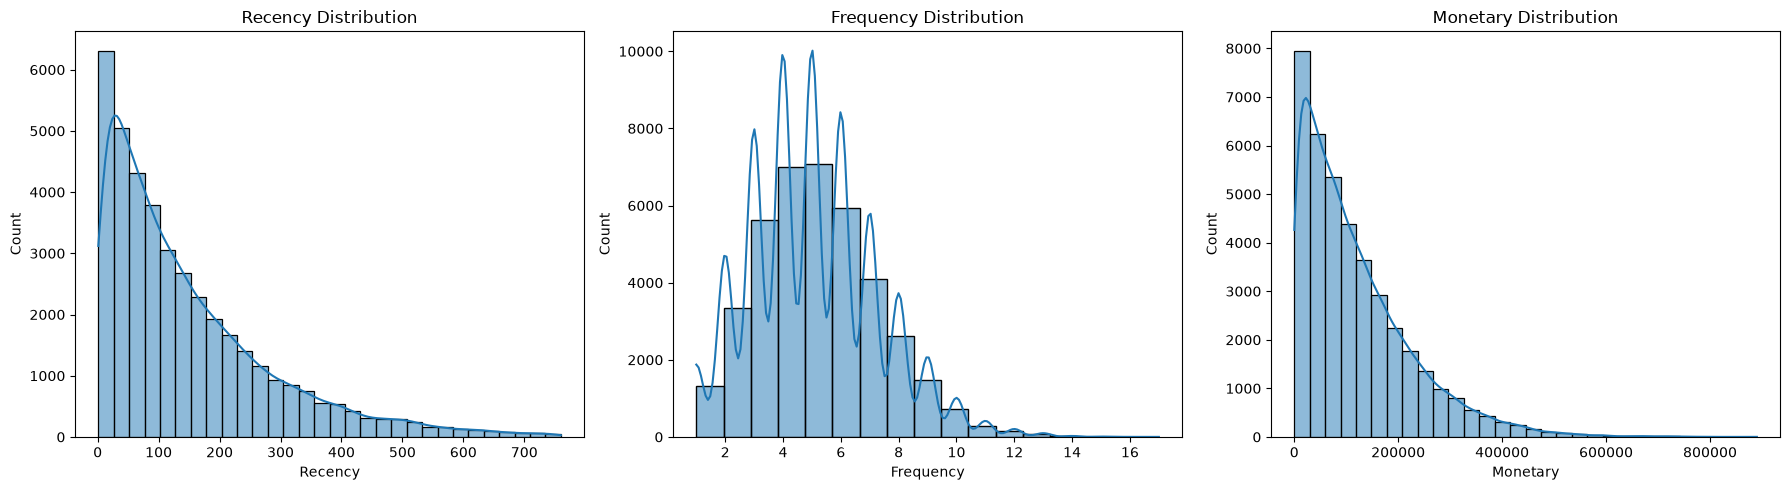

In [99]:

import matplotlib.pyplot as plt
import seaborn as sns

# Check missing values and duplicate customer records
print("Missing values in RFM:")
print(rfm[["Recency", "Frequency", "Monetary"]].isnull().sum())

print("\nDuplicate Customer_ID records:", rfm["Customer_ID"].duplicated().sum())

# Plot each RFM metric to inspect its distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=rfm, x="Recency", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(data=rfm, x="Frequency", bins=17, kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(data=rfm, x="Monetary", bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()


## Prepare RFM data for clustering

In [100]:

import numpy as np
from sklearn.preprocessing import StandardScaler

# Select only the three numerical RFM metrics for clustering
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Confirm all values are positive before applying log1p
print("Minimum RFM values:")
print(rfm_features.min())

# log1p reduces right skew and supports values equal to zero
# (your current RFM metrics are positive)
rfm_log = np.log1p(rfm_features)

# Standardize the transformed features:
# each feature will have approximately mean 0 and standard deviation 1
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert the scaled array back to a DataFrame for easy inspection
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

# Validate the prepared data
print("\nScaled RFM shape:", rfm_scaled_df.shape)

print("\nMissing values:")
print(rfm_scaled_df.isnull().sum())

print("\nScaled feature means (should be near 0):")
print(rfm_scaled_df.mean().round(3))

print("\nScaled feature standard deviations (should be near 1):")
print(rfm_scaled_df.std().round(3))

display(rfm_scaled_df.head())


Minimum RFM values:
Recency       1.0
Frequency     1.0
Monetary     93.8
dtype: float64

Scaled RFM shape: (39726, 3)

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Scaled feature means (should be near 0):
Recency     -0.0
Frequency   -0.0
Monetary     0.0
dtype: float64

Scaled feature standard deviations (should be near 1):
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


,Recency,Frequency,Monetary
0,0.562279,0.166272,-0.465147
1,0.384849,1.205763,-0.089157
2,0.975349,0.166272,1.138711
3,0.700702,-0.301146,-0.020752
4,0.372438,0.561468,0.821408


## Evaluate the optimal number of customer segments

K=2 | Inertia=75515.16 | Silhouette Score=0.3367
K=3 | Inertia=57660.91 | Silhouette Score=0.2912
K=4 | Inertia=47544.67 | Silhouette Score=0.2657
K=5 | Inertia=41531.99 | Silhouette Score=0.2702
K=6 | Inertia=36997.17 | Silhouette Score=0.2496
K=7 | Inertia=33438.94 | Silhouette Score=0.2504
K=8 | Inertia=30772.93 | Silhouette Score=0.2540


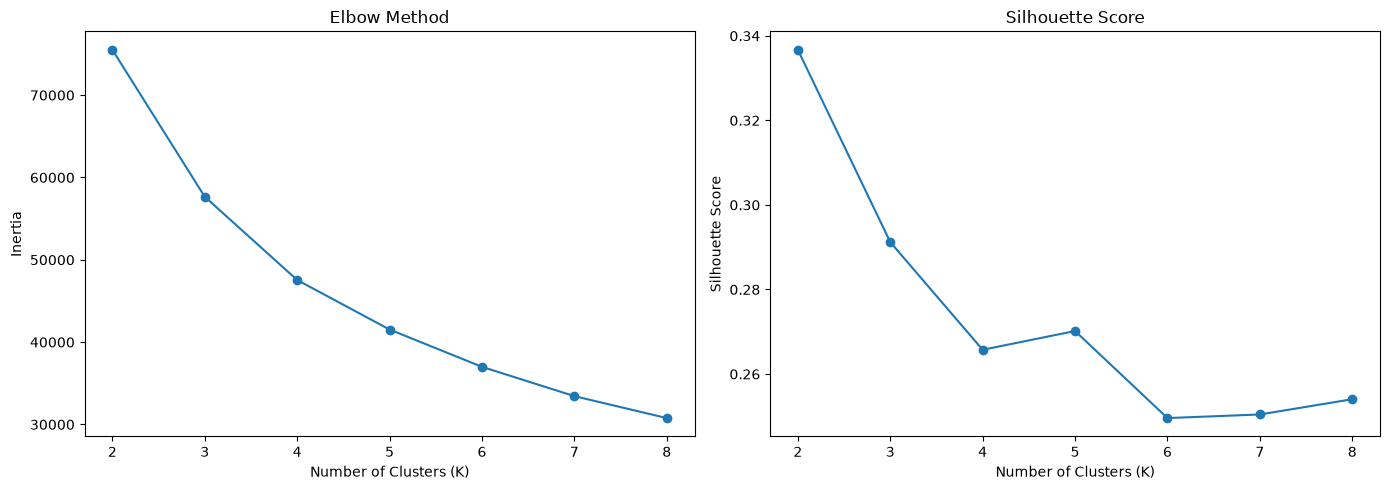

In [101]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Test cluster counts from 2 to 8
k_values = range(2, 9)
inertia_values = []
silhouette_scores = []

for k in k_values:
    # Create and train the K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    # Lower inertia generally means more compact clusters
    inertia_values.append(model.inertia_)

    # Use a consistent sample to estimate silhouette score efficiently
    score = silhouette_score(
        rfm_scaled_df,
        labels,
        sample_size=5000,
        random_state=42
    )
    silhouette_scores.append(score)

    print(
        f"K={k} | Inertia={model.inertia_:.2f} "
        f"| Silhouette Score={score:.4f}"
    )

# Compare the two evaluation methods visually
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()


In [102]:

from sklearn.cluster import KMeans

# Start with three customer segments for business interpretation
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign a cluster label to every customer
rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled_df)

# Check how many customers belong to each cluster
cluster_counts = rfm["Cluster"].value_counts().sort_index()

print("Customer count by cluster:")
print(cluster_counts)

# Display the percentage of customers in each cluster
print("\nCustomer percentage by cluster:")
print((cluster_counts / len(rfm) * 100).round(2))

# Summarize the original RFM metrics for each cluster
cluster_summary = (
    rfm.groupby("Cluster")
    .agg(
        Customer_Count=("Customer_ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median")
    )
    .round(2)
)

display(cluster_summary)


Customer count by cluster:
Cluster
0    10154
1    10534
2    19038
Name: count, dtype: int64

Customer percentage by cluster:
Cluster
0    25.56
1    26.52
2    47.92
Name: count, dtype: float64


,Customer_Count,Avg_Recency,Median_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary
Cluster,,,,,,
0,10154,246.38,207.0,2.76,30174.08,20189.52
1,10534,24.19,23.0,6.25,146930.62,120682.46
2,19038,163.33,135.0,5.59,151665.70,127080.38


## Visualize the customer segments

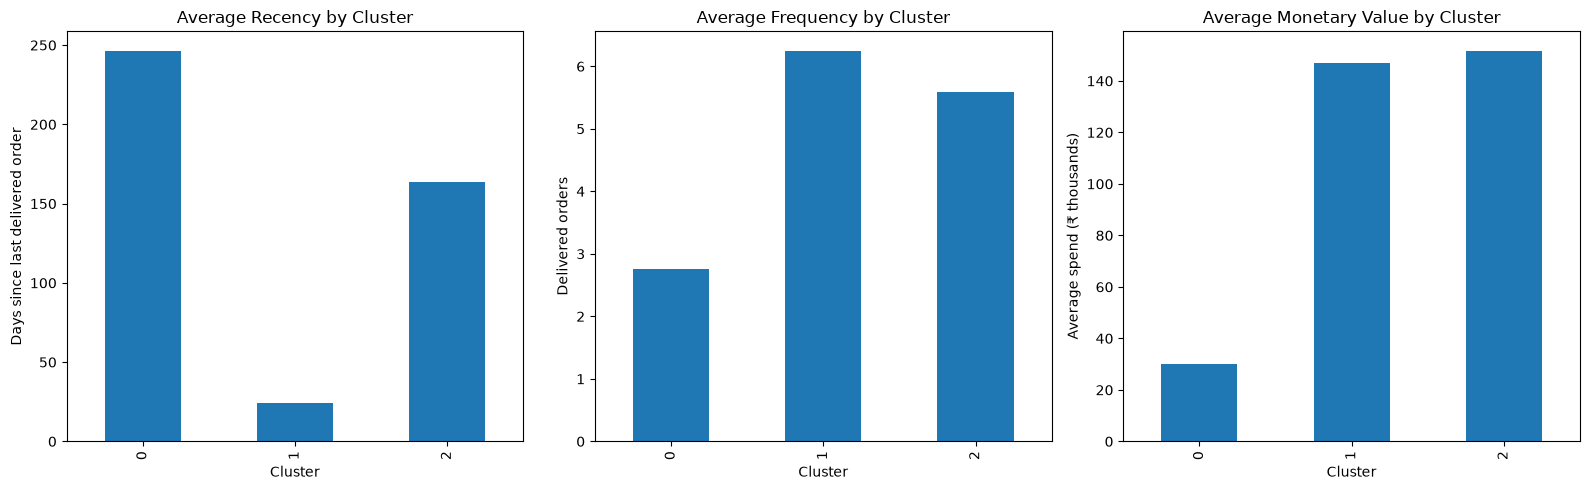

In [103]:

import matplotlib.pyplot as plt

# Calculate average RFM values for each cluster
cluster_means = (
    rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .mean()
)

# Create three separate charts to compare the clusters
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cluster_means["Recency"].plot(
    kind="bar", ax=axes[0], title="Average Recency by Cluster"
)
axes[0].set_ylabel("Days since last delivered order")
axes[0].set_xlabel("Cluster")

cluster_means["Frequency"].plot(
    kind="bar", ax=axes[1], title="Average Frequency by Cluster"
)
axes[1].set_ylabel("Delivered orders")
axes[1].set_xlabel("Cluster")

(cluster_means["Monetary"] / 1000).plot(
    kind="bar", ax=axes[2], title="Average Monetary Value by Cluster"
)
axes[2].set_ylabel("Average spend (₹ thousands)")
axes[2].set_xlabel("Cluster")

plt.tight_layout()
plt.show()


In [104]:

# Map the K-Means cluster IDs to readable business segment names
segment_names = {
    0: "At-Risk Low-Spending",
    1: "Recent High-Engagement",
    2: "Established High-Spending"
}

# Add the segment name to each customer's RFM record
rfm["Customer_Segment"] = rfm["Cluster"].map(segment_names)

# Review the number of customers in each named segment
segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("Customer_ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
    .sort_values("Customer_Count", ascending=False)
)

display(segment_summary)

# Verify every customer received a segment
print("\nMissing segment labels:", rfm["Customer_Segment"].isna().sum())
print("Total customers segmented:", rfm["Customer_ID"].nunique())


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Customer_Segment,,,,
Established High-Spending,19038,163.33,5.59,151665.70
Recent High-Engagement,10534,24.19,6.25,146930.62
At-Risk Low-Spending,10154,246.38,2.76,30174.08



Missing segment labels: 0
Total customers segmented: 39726


In [105]:

# Select the customer-level fields needed for reporting and dashboards
rfm_export = rfm[
    [
        "Customer_ID",
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster",
        "Customer_Segment"
    ]
].copy()

# Save the RFM segmentation results in the project data folder
rfm_export.to_csv(
    "../data/customer_rfm_segments.csv",
    index=False
)

print("RFM segmentation exported successfully!")
print("File: data/customer_rfm_segments.csv")
print("Rows exported:", len(rfm_export))

# Preview the exported dataset
display(rfm_export.head())


RFM segmentation exported successfully!
File: data/customer_rfm_segments.csv
Rows exported: 39726


,Customer_ID,Recency,Frequency,Monetary,Cluster,Customer_Segment
0,CUST00000001,170,5,40098.48,2,Established High-Spending
1,CUST00000002,138,8,63676.24,2,Established High-Spending
2,CUST00000004,276,5,288324.84,2,Established High-Spending
3,CUST00000005,200,4,69265.75,2,Established High-Spending
4,CUST00000006,136,6,195157.41,2,Established High-Spending


# 7. Exploratory Data Analysis (EDA)

## Analyze monthly revenue and orders

,Month,Monthly_Revenue,Monthly_Orders,Monthly_Quantity
0,2024-06-01,2.407817e+08,10008,12532
1,2024-07-01,2.409663e+08,10216,12785
2,2024-08-01,2.401946e+08,10158,12671
3,2024-09-01,2.293313e+08,9704,12077
4,2024-10-01,2.399716e+08,10034,12631


Number of months: 25
Total revenue: 5930693254.3
Total orders: 250000


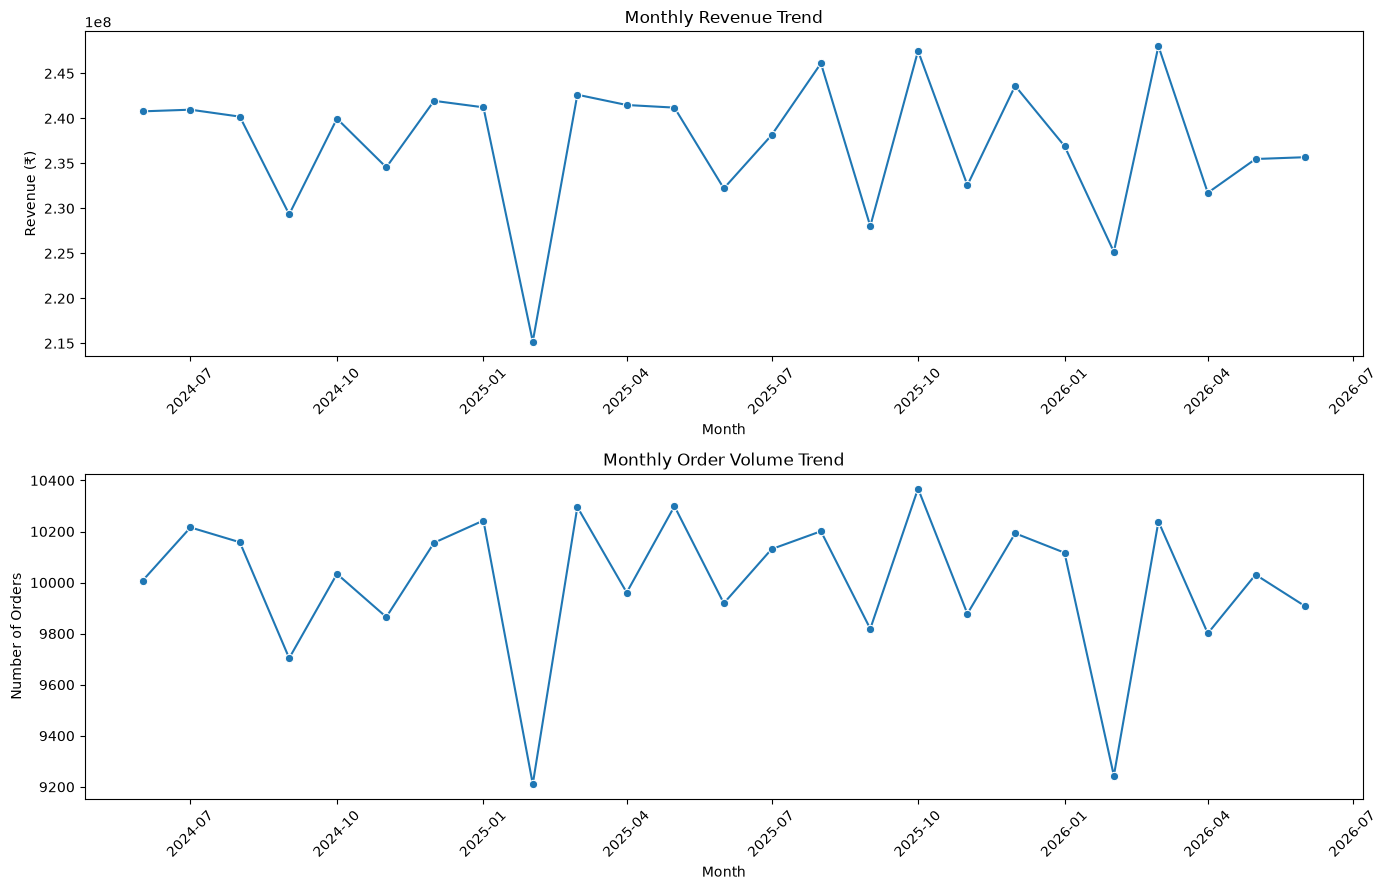

In [106]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate transaction data by month
monthly_sales = (
    sales_enriched
    .groupby("Order_Date")
    .agg(
        Monthly_Revenue=("Total_Amount", "sum"),
        Monthly_Orders=("Order_ID", "nunique"),
        Monthly_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Convert daily dates into monthly periods
monthly_sales["Month"] = (
    monthly_sales["Order_Date"].dt.to_period("M")
)

# Combine daily records into one row per month
monthly_sales = (
    monthly_sales
    .groupby("Month")
    .agg(
        Monthly_Revenue=("Monthly_Revenue", "sum"),
        Monthly_Orders=("Monthly_Orders", "sum"),
        Monthly_Quantity=("Monthly_Quantity", "sum")
    )
    .reset_index()
)

# Convert month periods to timestamps for plotting
monthly_sales["Month"] = monthly_sales["Month"].dt.to_timestamp()

# Display monthly business metrics
display(monthly_sales.head())
print("Number of months:", len(monthly_sales))
print("Total revenue:", round(monthly_sales["Monthly_Revenue"].sum(), 2))
print("Total orders:", monthly_sales["Monthly_Orders"].sum())

# Plot monthly revenue and order volume separately
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Monthly_Revenue",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_ylabel("Revenue (₹)")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Monthly_Orders",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Monthly Order Volume Trend")
axes[1].set_ylabel("Number of Orders")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [107]:

# Summarize order count and recorded transaction amount by status
status_summary = (
    sales_enriched
    .groupby("Order_Status")
    .agg(
        Order_Count=("Order_ID", "nunique"),
        Recorded_Amount=("Total_Amount", "sum"),
        Average_Amount=("Total_Amount", "mean")
    )
    .reset_index()
)

# Calculate each status's share of all orders
status_summary["Order_Percentage"] = (
    status_summary["Order_Count"]
    / sales_enriched["Order_ID"].nunique()
    * 100
)

# Display results with readable rounding
status_summary = status_summary.round(2)
display(status_summary.sort_values("Order_Count", ascending=False))


,Order_Status,Order_Count,Recorded_Amount,Average_Amount,Order_Percentage
1,Delivered,200139,4.741566e+09,23691.37,80.06
0,Cancelled,12507,3.021405e+08,24157.71,5.00
3,Returned,12493,3.004047e+08,24045.84,5.00
4,Shipped,12459,2.911208e+08,23366.31,4.98
2,Processing,12402,2.954608e+08,23823.64,4.96


## Compare delivered sales with all recorded orders

In [108]:

# Calculate recorded transaction amounts for all orders and delivered orders
total_recorded_amount = sales_enriched["Total_Amount"].sum()

delivered_sales = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

delivered_recorded_amount = delivered_sales["Total_Amount"].sum()

# Calculate delivered orders as a percentage of all unique orders
total_orders = sales_enriched["Order_ID"].nunique()
delivered_orders = delivered_sales["Order_ID"].nunique()

print(f"All recorded amount: ₹{total_recorded_amount:,.2f}")
print(f"Delivered recorded amount: ₹{delivered_recorded_amount:,.2f}")

print(
    f"Delivered order percentage: "
    f"{delivered_orders / total_orders * 100:.2f}%"
)

# Check whether delivered records contain negative amounts
negative_delivered = (delivered_sales["Total_Amount"] < 0).sum()
print("Negative delivered amounts:", negative_delivered)


All recorded amount: ₹5,930,693,254.30
Delivered recorded amount: ₹4,741,566,354.41
Delivered order percentage: 80.06%
Negative delivered amounts: 4


## Analyze revenue by product category

,Category,All_Order_Count,All_Recorded_Amount,Delivered_Order_Count,Delivered_Recorded_Amount,Revenue_Share_Percent
2,Electronics,66783,4.306350e+09,53576,3.443288e+09,72.62
5,Home,33653,7.161251e+08,26877,5.732860e+08,12.09
6,Sports,29341,4.758391e+08,23410,3.793918e+08,8.00
3,Fashion,49802,3.336788e+08,39842,2.665794e+08,5.62
4,Grocery,33402,4.177140e+07,26778,3.345878e+07,0.71
0,Beauty,16724,3.826580e+07,13427,3.065905e+07,0.65
1,Books,20295,1.866303e+07,16229,1.490332e+07,0.31


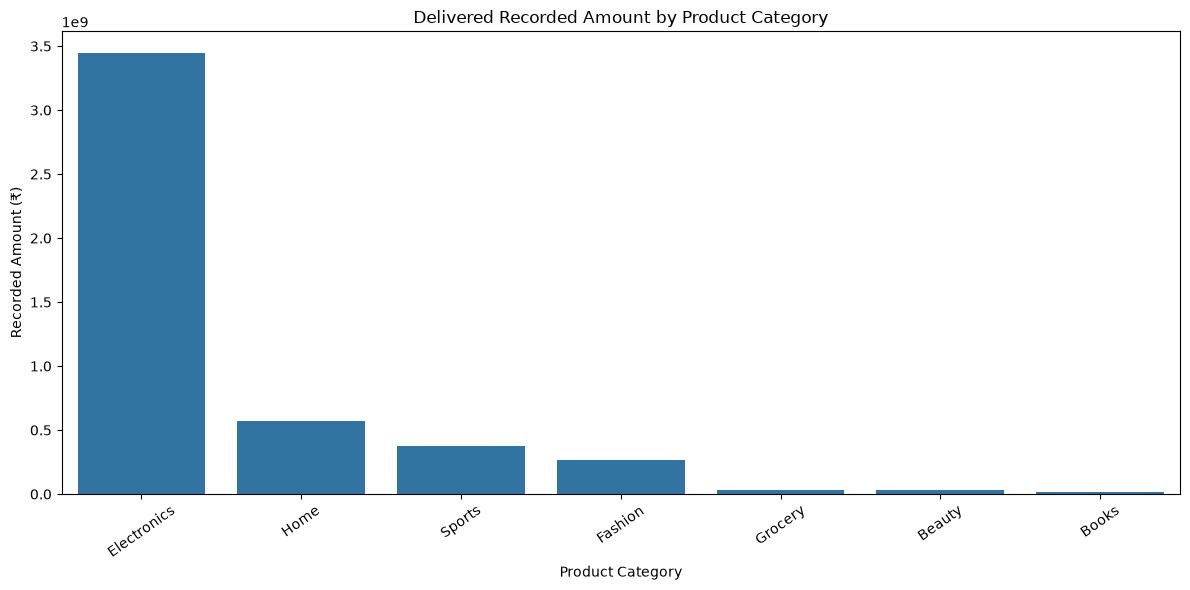

In [109]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate category performance across all order statuses
category_all = (
    sales_enriched
    .groupby("Category")
    .agg(
        All_Order_Count=("Order_ID", "nunique"),
        All_Recorded_Amount=("Total_Amount", "sum")
    )
    .reset_index()
)

# Calculate category performance for delivered orders only
category_delivered = (
    sales_enriched[
        sales_enriched["Order_Status"] == "Delivered"
    ]
    .groupby("Category")
    .agg(
        Delivered_Order_Count=("Order_ID", "nunique"),
        Delivered_Recorded_Amount=("Total_Amount", "sum")
    )
    .reset_index()
)

# Combine both summaries using the product category
category_summary = category_all.merge(
    category_delivered,
    on="Category",
    how="left"
)

# Calculate each category's contribution to delivered recorded amount
category_summary["Revenue_Share_Percent"] = (
    category_summary["Delivered_Recorded_Amount"]
    / category_summary["Delivered_Recorded_Amount"].sum()
    * 100
)

# Sort categories from highest to lowest delivered recorded amount
category_summary = category_summary.sort_values(
    "Delivered_Recorded_Amount",
    ascending=False
)

display(category_summary.round(2))

# Plot delivered recorded amount by category
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_summary,
    x="Category",
    y="Delivered_Recorded_Amount"
)

plt.title("Delivered Recorded Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Recorded Amount (₹)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


,Category,Delivered_Orders,Units_Sold,Delivered_Amount,Average_Order_Value,Revenue_Share_Percent
2,Electronics,53576,66757,3.443288e+09,64269.22,72.62
5,Home,26877,33680,5.732860e+08,21329.99,12.09
6,Sports,23410,29318,3.793918e+08,16206.40,8.00
3,Fashion,39842,49807,2.665794e+08,6690.91,5.62
4,Grocery,26778,33346,3.345878e+07,1249.49,0.71
0,Beauty,13427,16734,3.065905e+07,2283.39,0.65
1,Books,16229,20192,1.490332e+07,918.31,0.31


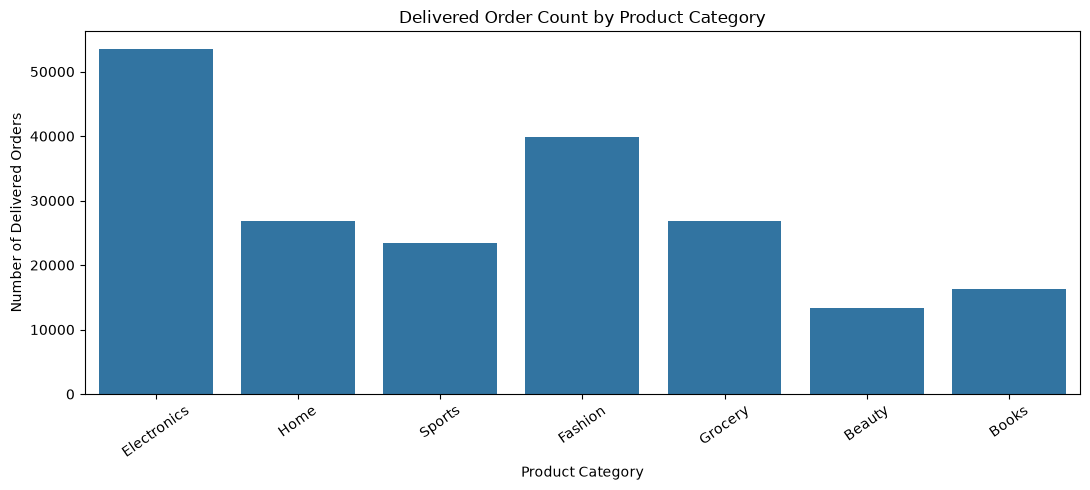

In [110]:

# Analyze delivered orders by product category
delivered_category_data = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

category_analysis = (
    delivered_category_data
    .groupby("Category")
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Delivered_Amount=("Total_Amount", "sum"),
        Average_Order_Value=("Total_Amount", "mean")
    )
    .reset_index()
)

# Calculate each category's percentage of delivered recorded amount
category_analysis["Revenue_Share_Percent"] = (
    category_analysis["Delivered_Amount"]
    / category_analysis["Delivered_Amount"].sum()
    * 100
)

# Sort by delivered recorded amount, highest first
category_analysis = category_analysis.sort_values(
    "Delivered_Amount",
    ascending=False
)

display(category_analysis.round(2))

# Plot order volume by category
plt.figure(figsize=(11, 5))
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Delivered_Orders"
)
plt.title("Delivered Order Count by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Delivered Orders")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


## Analyze payment preferences

,Payment_Mode,Order_Count,Recorded_Amount,Average_Amount,Order_Share_Percent
3,UPI,128474,3.176417e+09,24724.20,51.39
0,COD,82093,1.841909e+09,22436.86,32.84
2,Debit Card,28856,6.317076e+08,21891.72,11.54
1,Credit Card,10577,2.806600e+08,26534.93,4.23


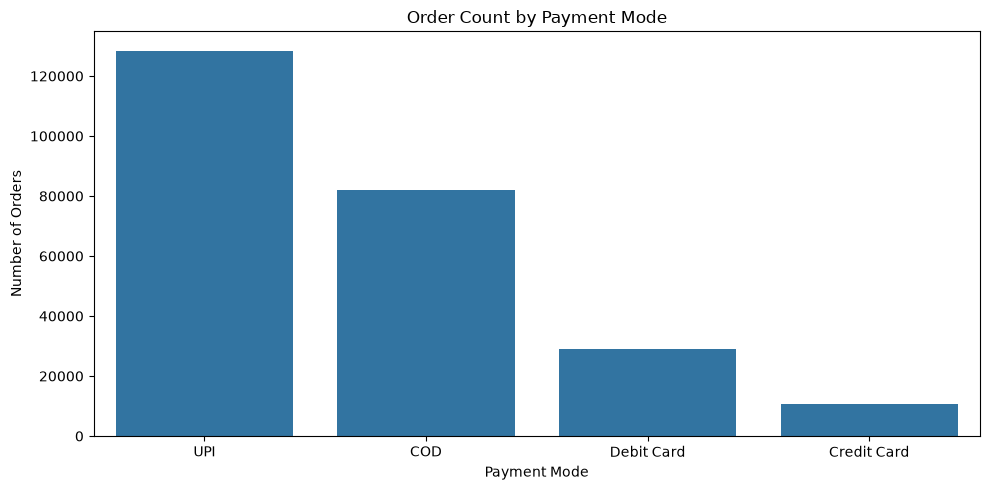

In [111]:

# Summarize order count and recorded amount by payment mode
payment_summary = (
    sales_enriched
    .groupby("Payment_Mode")
    .agg(
        Order_Count=("Order_ID", "nunique"),
        Recorded_Amount=("Total_Amount", "sum"),
        Average_Amount=("Total_Amount", "mean")
    )
    .reset_index()
)

# Calculate each payment mode's share of all orders
payment_summary["Order_Share_Percent"] = (
    payment_summary["Order_Count"]
    / sales_enriched["Order_ID"].nunique()
    * 100
)

# Sort by number of orders
payment_summary = payment_summary.sort_values(
    "Order_Count",
    ascending=False
)

display(payment_summary.round(2))

# Plot order count by payment mode
plt.figure(figsize=(10, 5))
sns.barplot(
    data=payment_summary,
    x="Payment_Mode",
    y="Order_Count"
)
plt.title("Order Count by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


,Payment_Mode,Total_Orders,Cancelled_Orders,Returned_Orders,Cancellation_Rate_Percent,Return_Rate_Percent
0,COD,82093,4023,4184,4.90,5.10
1,Credit Card,10577,530,540,5.01,5.11
2,Debit Card,28856,1453,1447,5.04,5.01
3,UPI,128474,6501,6322,5.06,4.92


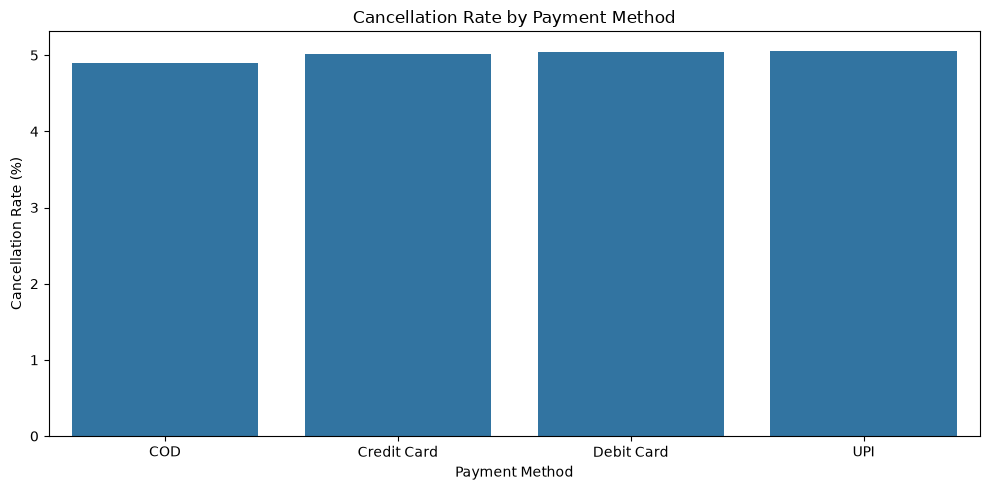

In [112]:

# Create a flag for cancelled and returned orders
payment_outcomes = sales_enriched.copy()

payment_outcomes["Is_Cancelled"] = (
    payment_outcomes["Order_Status"] == "Cancelled"
)

payment_outcomes["Is_Returned"] = (
    payment_outcomes["Order_Status"] == "Returned"
)

# Summarize order outcomes for each payment mode
payment_status_summary = (
    payment_outcomes
    .groupby("Payment_Mode")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Cancelled_Orders=("Is_Cancelled", "sum"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)

# Calculate cancellation and return rates within each payment mode
payment_status_summary["Cancellation_Rate_Percent"] = (
    payment_status_summary["Cancelled_Orders"]
    / payment_status_summary["Total_Orders"]
    * 100
)

payment_status_summary["Return_Rate_Percent"] = (
    payment_status_summary["Returned_Orders"]
    / payment_status_summary["Total_Orders"]
    * 100
)

display(payment_status_summary.round(2))

# Plot cancellation rates by payment mode
plt.figure(figsize=(10, 5))
sns.barplot(
    data=payment_status_summary,
    x="Payment_Mode",
    y="Cancellation_Rate_Percent"
)
plt.title("Cancellation Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()


## Analyze customer geography

,State,Delivered_Orders,Delivered_Amount,Average_Amount,Unique_Customers,Amount_Share_Percent
8,UP,26134,6.187059e+08,23674.37,5186,13.05
6,Rajasthan,25440,6.047446e+08,23771.41,5032,12.75
2,Haryana,25656,5.977207e+08,23297.50,5091,12.61
4,Maharashtra,20364,4.847609e+08,23804.80,4028,10.22
5,Punjab,20240,4.768408e+08,23559.33,4058,10.06
1,Gujarat,20141,4.760159e+08,23634.18,3989,10.04
0,Delhi,15614,3.816592e+08,24443.40,3095,8.05
7,Tamil Nadu,15804,3.759771e+08,23790.00,3144,7.93
9,West Bengal,15514,3.647380e+08,23510.25,3111,7.69
3,Karnataka,15232,3.604033e+08,23660.93,2992,7.60


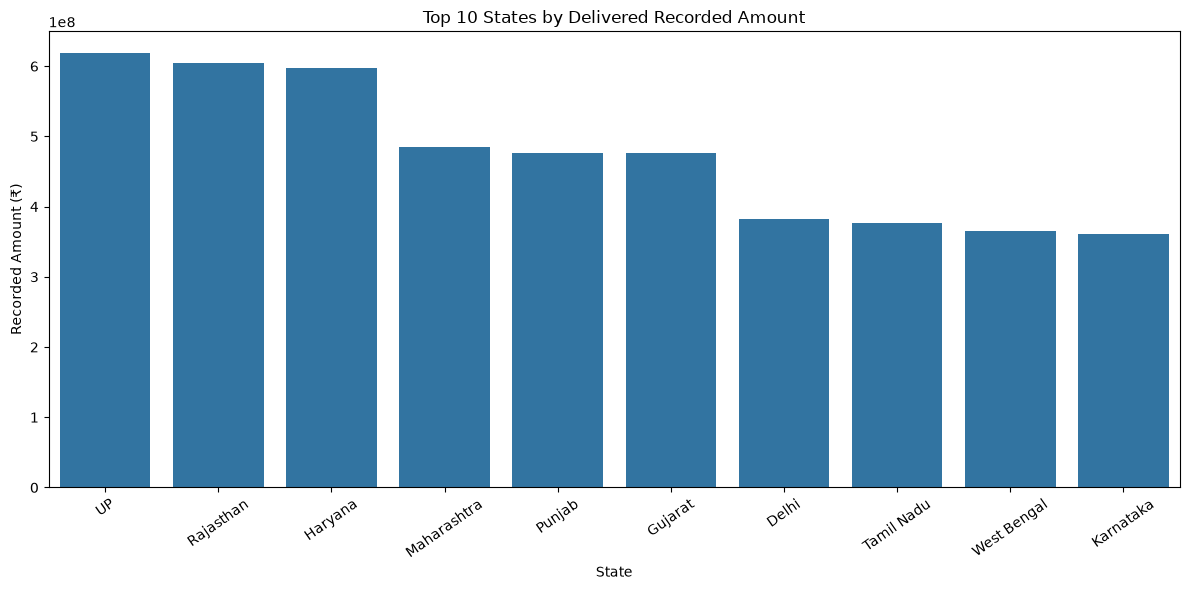

In [113]:

# Keep delivered orders for a completed-purchase analysis
delivered_sales = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

# Aggregate delivered performance by state
state_summary = (
    delivered_sales
    .groupby("State")
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Delivered_Amount=("Total_Amount", "sum"),
        Average_Amount=("Total_Amount", "mean"),
        Unique_Customers=("Customer_ID", "nunique")
    )
    .reset_index()
)

# Calculate each state's share of delivered recorded amount
state_summary["Amount_Share_Percent"] = (
    state_summary["Delivered_Amount"]
    / state_summary["Delivered_Amount"].sum()
    * 100
)

# Sort states by delivered recorded amount
state_summary = state_summary.sort_values(
    "Delivered_Amount",
    ascending=False
)

display(state_summary.round(2))

# Plot the top 10 states by delivered recorded amount
top_states = state_summary.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_states,
    x="State",
    y="Delivered_Amount"
)
plt.title("Top 10 States by Delivered Recorded Amount")
plt.xlabel("State")
plt.ylabel("Recorded Amount (₹)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


,State,Delivered_Orders,Avg_Delivery_Days,Median_Delivery_Days,Fast_Delivery_Count,Slow_Delivery_Count,Slow_Delivery_Percent
1,Gujarat,20141,4.51,5.0,6697,6773,33.63
2,Haryana,25656,4.51,5.0,8466,8667,33.78
8,UP,26134,4.50,5.0,8747,8758,33.51
7,Tamil Nadu,15804,4.50,5.0,5209,5257,33.26
0,Delhi,15614,4.50,5.0,5251,5226,33.47
4,Maharashtra,20364,4.50,5.0,6824,6874,33.76
6,Rajasthan,25440,4.49,4.0,8440,8482,33.34
3,Karnataka,15232,4.49,5.0,5118,5082,33.36
5,Punjab,20240,4.49,4.0,6828,6733,33.27
9,West Bengal,15514,4.49,4.0,5238,5112,32.95


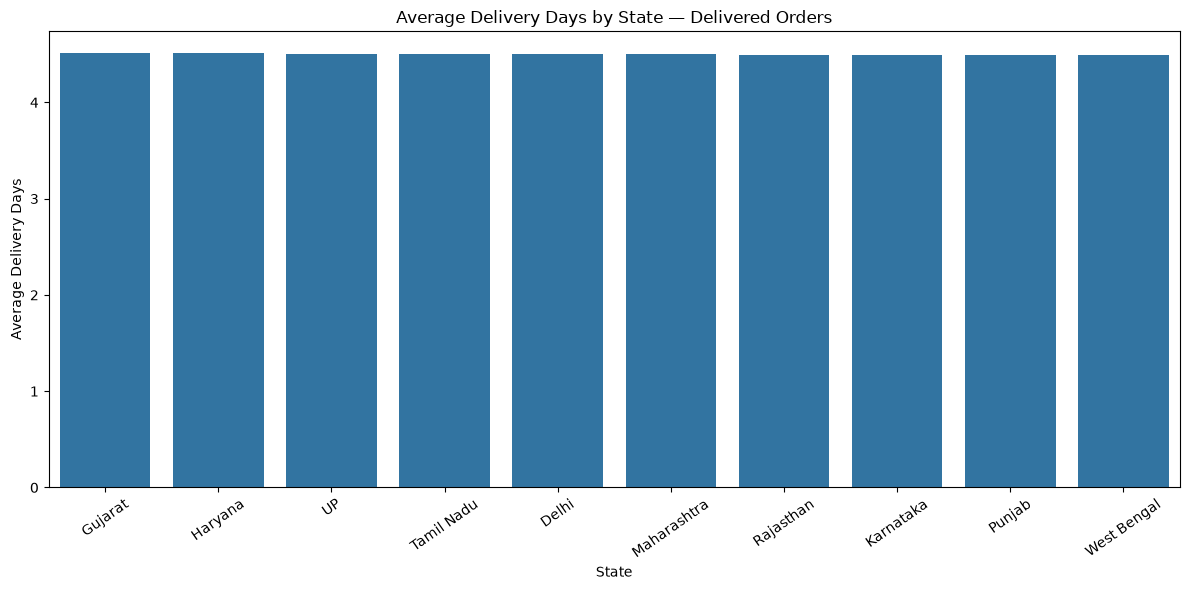

In [114]:

# Use delivered orders to analyze completed-order delivery performance
delivered_sales = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

# Summarize delivery time by state
delivery_state_summary = (
    delivered_sales
    .groupby("State")
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Avg_Delivery_Days=("Delivery_Days", "mean"),
        Median_Delivery_Days=("Delivery_Days", "median"),
        Fast_Delivery_Count=(
            "Delivery_Speed_Category",
            lambda x: (x == "Fast").sum()
        ),
        Slow_Delivery_Count=(
            "Delivery_Speed_Category",
            lambda x: (x == "Slow").sum()
        )
    )
    .reset_index()
)

# Calculate the percentage of delivered orders categorized as slow
delivery_state_summary["Slow_Delivery_Percent"] = (
    delivery_state_summary["Slow_Delivery_Count"]
    / delivery_state_summary["Delivered_Orders"]
    * 100
)

# Sort by average delivery time, highest first
delivery_state_summary = delivery_state_summary.sort_values(
    "Avg_Delivery_Days",
    ascending=False
)

display(delivery_state_summary.round(2))

# Plot average delivery days by state
plt.figure(figsize=(12, 6))
sns.barplot(
    data=delivery_state_summary,
    x="State",
    y="Avg_Delivery_Days"
)
plt.title("Average Delivery Days by State — Delivered Orders")
plt.xlabel("State")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


## Analyze monthly order-status trends

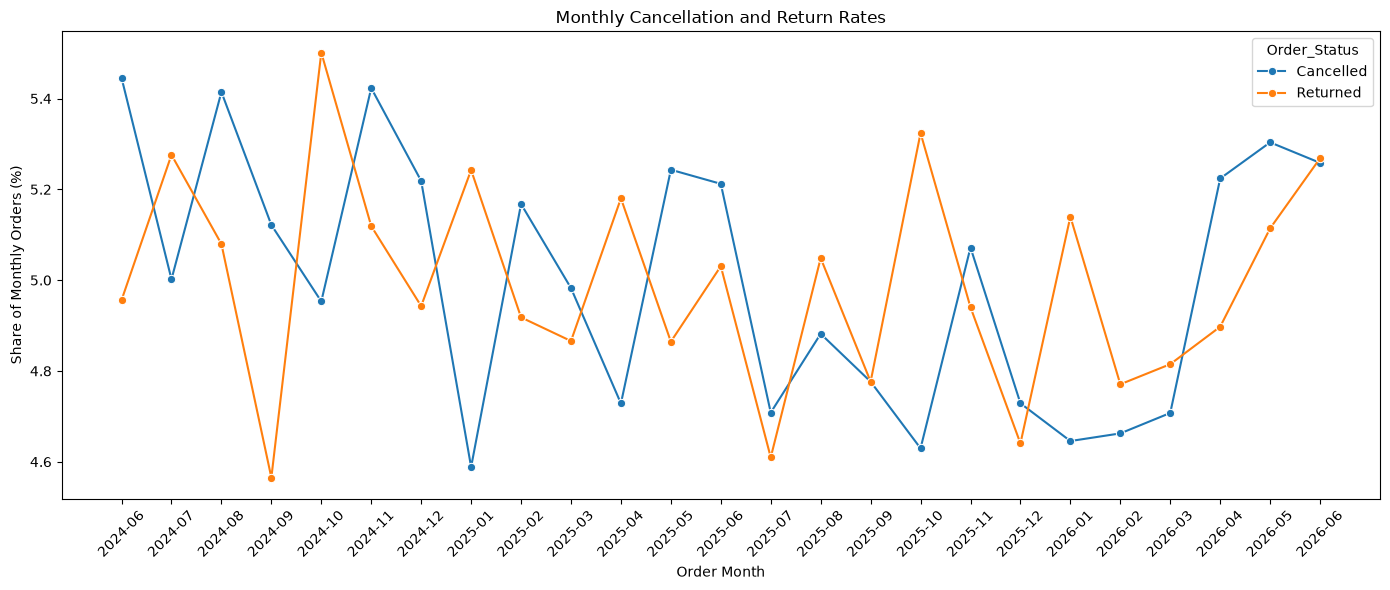

,Order_Month,Order_Status,Order_Count,Status_Percent
65,2025-07,Cancelled,477,4.71
68,2025-07,Returned,467,4.61
70,2025-08,Cancelled,498,4.88
73,2025-08,Returned,515,5.05
75,2025-09,Cancelled,469,4.78
78,2025-09,Returned,469,4.78
80,2025-10,Cancelled,480,4.63
83,2025-10,Returned,552,5.32
85,2025-11,Cancelled,501,5.07
88,2025-11,Returned,488,4.94


In [115]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a monthly period from the order date
status_monthly = sales_enriched.copy()

status_monthly["Order_Month"] = (
    status_monthly["Order_Date"].dt.to_period("M")
)

# Count orders by month and status
monthly_status_counts = (
    status_monthly
    .groupby(["Order_Month", "Order_Status"])
    .agg(Order_Count=("Order_ID", "nunique"))
    .reset_index()
)

# Calculate the total number of orders per month
monthly_totals = (
    monthly_status_counts
    .groupby("Order_Month")["Order_Count"]
    .sum()
    .rename("Total_Orders")
)

# Attach monthly totals to each status record
monthly_status_counts = monthly_status_counts.merge(
    monthly_totals,
    on="Order_Month"
)

# Calculate each status's percentage of orders within its month
monthly_status_counts["Status_Percent"] = (
    monthly_status_counts["Order_Count"]
    / monthly_status_counts["Total_Orders"]
    * 100
)

# Convert the month period to a string for plotting
monthly_status_counts["Order_Month"] = (
    monthly_status_counts["Order_Month"].astype(str)
)

# Plot cancellation and return percentages over time
focus_statuses = monthly_status_counts[
    monthly_status_counts["Order_Status"].isin(
        ["Cancelled", "Returned"]
    )
]

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=focus_statuses,
    x="Order_Month",
    y="Status_Percent",
    hue="Order_Status",
    marker="o"
)
plt.title("Monthly Cancellation and Return Rates")
plt.xlabel("Order Month")
plt.ylabel("Share of Monthly Orders (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display the latest 12 months of cancellation and return rates
display(
    focus_statuses[
        ["Order_Month", "Order_Status", "Order_Count", "Status_Percent"]
    ].tail(24).round(2)
)


## Analyze customer-tier performance

,Customer_Tier,Delivered_Orders,Unique_Customers,Delivered_Amount,Average_Amount_Per_Order,Amount_Share_Percent,Amount_Per_Customer
0,Gold,28674,6692,2.324346e+08,8106.11,4.90,34733.20
1,Platinum,153476,27349,4.455365e+09,29029.72,93.96,162907.79
2,Silver,17989,5685,5.376676e+07,2988.87,1.13,9457.65


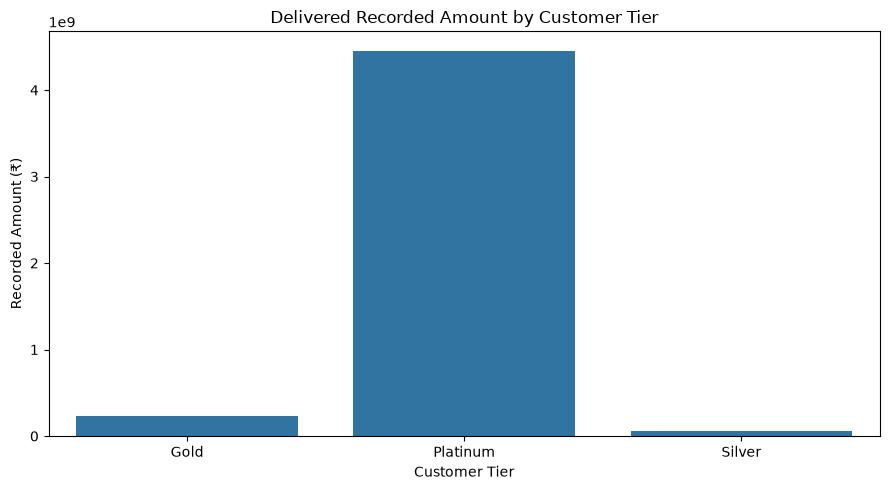

In [116]:

# Analyze delivered orders by customer tier
delivered_sales = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

tier_summary = (
    delivered_sales
    .groupby("Customer_Tier")
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Unique_Customers=("Customer_ID", "nunique"),
        Delivered_Amount=("Total_Amount", "sum"),
        Average_Amount_Per_Order=("Total_Amount", "mean")
    )
    .reset_index()
)

# Calculate each tier's share of delivered recorded amount
tier_summary["Amount_Share_Percent"] = (
    tier_summary["Delivered_Amount"]
    / tier_summary["Delivered_Amount"].sum()
    * 100
)

# Calculate the average delivered amount per customer
tier_summary["Amount_Per_Customer"] = (
    tier_summary["Delivered_Amount"]
    / tier_summary["Unique_Customers"]
)

display(tier_summary.round(2))

# Visualize delivered recorded amount by tier
plt.figure(figsize=(9, 5))
sns.barplot(
    data=tier_summary,
    x="Customer_Tier",
    y="Delivered_Amount"
)
plt.title("Delivered Recorded Amount by Customer Tier")
plt.xlabel("Customer Tier")
plt.ylabel("Recorded Amount (₹)")
plt.tight_layout()
plt.show()


,Customer_Tier,Unique_Customers,Avg_Orders_Per_Customer,Median_Orders_Per_Customer,Avg_Spend_Per_Customer,Median_Spend_Per_Customer
0,Gold,6692,4.28,4.0,34733.20,34704.92
1,Platinum,27349,5.61,5.0,162907.79,135144.88
2,Silver,5685,3.16,3.0,9457.65,8962.28


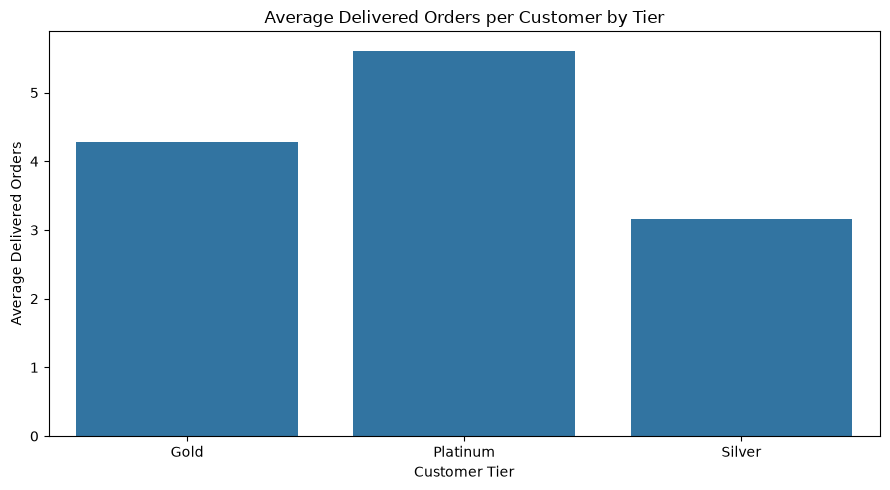

In [117]:

# Summarize delivered purchasing behavior at the customer level
delivered_customer_behavior = (
    delivered_sales
    .groupby(["Customer_Tier", "Customer_ID"])
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Customer_Spend=("Total_Amount", "sum")
    )
    .reset_index()
)

# Aggregate the customer-level metrics by tier
tier_behavior = (
    delivered_customer_behavior
    .groupby("Customer_Tier")
    .agg(
        Unique_Customers=("Customer_ID", "nunique"),
        Avg_Orders_Per_Customer=("Delivered_Orders", "mean"),
        Median_Orders_Per_Customer=("Delivered_Orders", "median"),
        Avg_Spend_Per_Customer=("Customer_Spend", "mean"),
        Median_Spend_Per_Customer=("Customer_Spend", "median")
    )
    .reset_index()
)

display(tier_behavior.round(2))

# Compare average delivered orders per customer across tiers
plt.figure(figsize=(9, 5))
sns.barplot(
    data=tier_behavior,
    x="Customer_Tier",
    y="Avg_Orders_Per_Customer"
)
plt.title("Average Delivered Orders per Customer by Tier")
plt.xlabel("Customer Tier")
plt.ylabel("Average Delivered Orders")
plt.tight_layout()
plt.show()


In [118]:

# Use delivered orders for this analysis
delivered_sales = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

# Create discount bands from the existing coupon discount percentage
delivered_sales["Discount_Band"] = pd.cut(
    delivered_sales["Coupon_Discount"],
    bins=[-0.01, 0, 5, 10, 20, 100],
    labels=[
        "No Discount",
        "0-5%",
        "5-10%",
        "10-20%",
        "20%+"
    ],
    include_lowest=True
)

# Compare order count, discount, and recorded amount by discount band
discount_summary = (
    delivered_sales
    .groupby("Discount_Band", observed=False)
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Avg_Coupon_Discount=("Coupon_Discount", "mean"),
        Delivered_Amount=("Total_Amount", "sum"),
        Avg_Amount_Per_Order=("Total_Amount", "mean")
    )
    .reset_index()
)

# Calculate each band's share of delivered recorded amount
discount_summary["Amount_Share_Percent"] = (
    discount_summary["Delivered_Amount"]
    / discount_summary["Delivered_Amount"].sum()
    * 100
)

display(discount_summary.round(2))


,Discount_Band,Delivered_Orders,Avg_Coupon_Discount,Delivered_Amount,Avg_Amount_Per_Order,Amount_Share_Percent
0,No Discount,159983,0.00,3.810206e+09,23816.32,88.49
1,0-5%,35,3.94,3.707320e+03,105.92,0.00
2,5-10%,102,7.21,1.367991e+04,134.12,0.00
3,10-20%,267,15.09,5.487505e+04,205.52,0.00
4,20%+,22707,73.12,4.957681e+08,21833.27,11.51


In [119]:

# Inspect coupon discount amounts in delivered orders
print("Coupon_Discount summary:")
display(delivered_sales["Coupon_Discount"].describe())

print("\nUnique coupon discount values (first 20):")
print(
    sorted(delivered_sales["Coupon_Discount"].dropna().unique())[:20]
)

# Check how coupon discount relates to coupon-code usage
print("\nCoupon discount by coupon presence:")
display(
    delivered_sales
    .groupby("Has_Coupon")
    .agg(
        Order_Count=("Order_ID", "nunique"),
        Avg_Coupon_Discount=("Coupon_Discount", "mean"),
        Total_Coupon_Discount=("Coupon_Discount", "sum")
    )
    .round(2)
)

# Inspect product-level discount percentages separately
print("\nProduct discount percentage summary:")
display(products_clean["Discount_Percent"].describe())


Coupon_Discount summary:


count    200139.000000
mean        250.108287
std        1392.625739
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max       38279.160000
Name: Coupon_Discount, dtype: float64


Unique coupon discount values (first 20):
[np.float64(0.0), np.float64(2.61), np.float64(3.56), np.float64(4.76), np.float64(4.79), np.float64(5.23), np.float64(5.25), np.float64(5.33), np.float64(5.85), np.float64(6.3), np.float64(6.7), np.float64(7.11), np.float64(7.13), np.float64(7.16), np.float64(7.23), np.float64(8.07), np.float64(8.1), np.float64(8.22), np.float64(8.26), np.float64(9.28)]

Coupon discount by coupon presence:


,Order_Count,Avg_Coupon_Discount,Total_Coupon_Discount
Has_Coupon,,,
False,159983,0.00,0.00
True,40156,1246.55,50056422.55



Product discount percentage summary:


count    2000.000000
mean       27.471000
std        13.309874
min         5.000000
25%        16.000000
50%        27.000000
75%        39.000000
max        50.000000
Name: Discount_Percent, dtype: float64

In [120]:

# Compare delivered orders based on whether a coupon was used
coupon_summary = (
    delivered_sales
    .groupby("Has_Coupon")
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Delivered_Amount=("Total_Amount", "sum"),
        Average_Amount_Per_Order=("Total_Amount", "mean"),
        Total_Coupon_Discount=("Coupon_Discount", "sum"),
        Average_Coupon_Discount=("Coupon_Discount", "mean")
    )
    .reset_index()
)

# Calculate the share of delivered orders in each group
coupon_summary["Order_Share_Percent"] = (
    coupon_summary["Delivered_Orders"]
    / coupon_summary["Delivered_Orders"].sum()
    * 100
)

# Calculate each group's share of delivered recorded amount
coupon_summary["Amount_Share_Percent"] = (
    coupon_summary["Delivered_Amount"]
    / coupon_summary["Delivered_Amount"].sum()
    * 100
)

display(coupon_summary.round(2))


,Has_Coupon,Delivered_Orders,Delivered_Amount,Average_Amount_Per_Order,Total_Coupon_Discount,Average_Coupon_Discount,Order_Share_Percent,Amount_Share_Percent
0,False,159983,3.810206e+09,23816.32,0.00,0.00,79.94,80.36
1,True,40156,9.313605e+08,23193.56,50056422.55,1246.55,20.06,19.64


In [121]:

# Import pandas if it is not already imported
import pandas as pd

# Use the enriched dataset containing sales, customer, and product details
df = sales_enriched

# Separate delivered orders for reconciliation
delivered_df = df[df["Order_Status"] == "Delivered"].copy()

# Calculate overall KPIs
total_rows = len(df)
unique_orders = df["Order_ID"].nunique()
unique_customers = df["Customer_ID"].nunique()
unique_products = df["Product_ID"].nunique()

# Calculate order counts by status
status_counts = df.groupby("Order_Status")["Order_ID"].nunique()
status_total = status_counts.sum()

# Calculate recorded amounts
all_status_amount = df["Total_Amount"].sum()
delivered_amount = delivered_df["Total_Amount"].sum()

# Calculate missing ratings
missing_ratings = df["Rating"].isna().sum()

# Create a readable KPI summary
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total sales records",
        "Unique orders",
        "Unique customers",
        "Unique products",
        "Delivered orders",
        "Delivered recorded amount (₹)",
        "All-status recorded amount (₹)",
        "Missing ratings"
    ],
    "Value": [
        total_rows,
        unique_orders,
        unique_customers,
        unique_products,
        len(delivered_df),
        round(delivered_amount, 2),
        round(all_status_amount, 2),
        missing_ratings
    ]
})

display(kpi_summary)

# Validate that status counts reconcile to the total order count
print("\n--- Validation Results ---")
print("One row per unique order:", df["Order_ID"].is_unique)
print("All status counts reconcile:", status_total == unique_orders)
print("Delivered order count matches expected value:",
      len(delivered_df) == 200139)
print("Unique customer count matches expected value:",
      unique_customers == 39914)
print("Unique product count matches expected value:",
      unique_products == 2000)


,Metric,Value
0,Total sales records,2.500000e+05
1,Unique orders,2.500000e+05
2,Unique customers,3.991400e+04
3,Unique products,2.000000e+03
4,Delivered orders,2.001390e+05
5,Delivered recorded amount (₹),4.741566e+09
6,All-status recorded amount (₹),5.930693e+09
7,Missing ratings,1.299700e+05



--- Validation Results ---
One row per unique order: True
All status counts reconcile: True
Delivered order count matches expected value: True
Unique customer count matches expected value: True
Unique product count matches expected value: True


In [122]:

# Filter only delivered orders
delivered_df = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

# Calculate the total recorded amount from all delivered orders
overall_delivered_amount = delivered_df["Total_Amount"].sum()

# Calculate the recorded amount for each product category
category_amounts = (
    delivered_df.groupby("Category")["Total_Amount"]
    .agg(["sum", "count"])
    .reset_index()
)

# Rename columns to make the output easier to understand
category_amounts.columns = [
    "Category",
    "Delivered_Recorded_Amount",
    "Delivered_Order_Count"
]

# Calculate each category's share of the delivered recorded amount
category_amounts["Amount_Share_Percent"] = (
    category_amounts["Delivered_Recorded_Amount"]
    / overall_delivered_amount * 100
).round(2)

# Display categories from highest to lowest recorded amount
category_amounts = category_amounts.sort_values(
    "Delivered_Recorded_Amount", ascending=False
)

display(category_amounts)

# Compare the category total against the overall delivered amount
category_total = category_amounts["Delivered_Recorded_Amount"].sum()
difference = overall_delivered_amount - category_total

print("\n--- Category Reconciliation ---")
print(f"Overall delivered recorded amount: ₹{overall_delivered_amount:,.2f}")
print(f"Sum of category amounts:           ₹{category_total:,.2f}")
print(f"Difference:                        ₹{difference:,.2f}")
print("Amounts reconcile:", abs(difference) < 0.01)

# Verify category shares total approximately 100%
share_total = category_amounts["Amount_Share_Percent"].sum()
print(f"Sum of rounded category shares: {share_total:.2f}%")


,Category,Delivered_Recorded_Amount,Delivered_Order_Count,Amount_Share_Percent
2,Electronics,3.443288e+09,53576,72.62
5,Home,5.732860e+08,26877,12.09
6,Sports,3.793918e+08,23410,8.00
3,Fashion,2.665794e+08,39842,5.62
4,Grocery,3.345878e+07,26778,0.71
0,Beauty,3.065905e+07,13427,0.65
1,Books,1.490332e+07,16229,0.31



--- Category Reconciliation ---
Overall delivered recorded amount: ₹4,741,566,354.41
Sum of category amounts:           ₹4,741,566,354.41
Difference:                        ₹0.00
Amounts reconcile: True
Sum of rounded category shares: 100.00%


In [123]:

# 1. Check missing values in important fields
important_columns = [
    "Order_ID",
    "Customer_ID",
    "Product_ID",
    "Order_Date",
    "Order_Status",
    "Category",
    "Total_Amount"
]

print("--- Missing Values in Important Columns ---")
display(
    sales_enriched[important_columns]
    .isnull()
    .sum()
    .rename("Missing_Count")
    .to_frame()
)

# 2. Check negative recorded amounts among delivered orders
delivered_df = sales_enriched[
    sales_enriched["Order_Status"] == "Delivered"
].copy()

negative_delivered = delivered_df[
    delivered_df["Total_Amount"] < 0
]

print("\n--- Negative Delivered Amounts ---")
print("Negative delivered records:", len(negative_delivered))
print(
    "Total negative recorded amount: ₹",
    round(negative_delivered["Total_Amount"].sum(), 2)
)

# 3. Validate the daily time series
print("\n--- Daily Time Series Validation ---")

print("Number of daily records:", len(daily_sales))
print("First date:", daily_sales["Order_Date"].min())
print("Last date:", daily_sales["Order_Date"].max())

# Confirm that dates are continuous with no missing calendar days
expected_days = (
    daily_sales["Order_Date"].max()
    - daily_sales["Order_Date"].min()
).days + 1

print("Expected calendar days:", expected_days)
print("Dates are continuous:", len(daily_sales) == expected_days)

# Lag and rolling features should have missing values only at the start
# because earlier dates are unavailable for those calculations.
time_features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Revenue_Lag_30",
    "Revenue_Rolling_Mean_7",
    "Revenue_Rolling_Mean_30"
]

print("\nMissing values in time-series features:")
display(daily_sales[time_features].isnull().sum().to_frame("Missing_Count"))


--- Missing Values in Important Columns ---


,Missing_Count
Order_ID,0
Customer_ID,0
Product_ID,0
Order_Date,0
Order_Status,0
Category,0
Total_Amount,0



--- Negative Delivered Amounts ---
Negative delivered records: 4
Total negative recorded amount: ₹ -51.41

--- Daily Time Series Validation ---
Number of daily records: 760
First date: 2024-06-01 00:00:00
Last date: 2026-06-30 00:00:00
Expected calendar days: 760
Dates are continuous: True

Missing values in time-series features:


,Missing_Count
Revenue_Lag_1,1
Revenue_Lag_7,7
Revenue_Lag_30,30
Revenue_Rolling_Mean_7,7
Revenue_Rolling_Mean_30,30


# 8. Business KPI

## Business KPIs and Insights

In [124]:

# BUSINESS KPI CALCULATION

import pandas as pd

# Use the enriched dataset created during feature engineering
df = sales_enriched.copy()

# Separate delivered orders from all order statuses
delivered = df[df["Order_Status"] == "Delivered"].copy()

# 1. Order metrics
total_orders = df["Order_ID"].nunique()
delivered_orders = delivered["Order_ID"].nunique()

# 2. Order status rates (denominator = all orders)
cancelled_orders = df.loc[
    df["Order_Status"] == "Cancelled", "Order_ID"
].nunique()

returned_orders = df.loc[
    df["Order_Status"] == "Returned", "Order_ID"
].nunique()

delivered_rate = delivered_orders / total_orders * 100
cancellation_rate = cancelled_orders / total_orders * 100
return_rate = returned_orders / total_orders * 100

# 3. Recorded amount metrics
all_status_amount = df["Total_Amount"].sum()
delivered_amount = delivered["Total_Amount"].sum()

# Average recorded amount per delivered order
average_delivered_order_amount = (
    delivered_amount / delivered_orders
)

# 4. Customer metrics
total_customers = df["Customer_ID"].nunique()
delivered_customers = delivered["Customer_ID"].nunique()

# 5. Create a summary table
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Delivered Orders",
        "Delivered Order Rate (%)",
        "Cancelled Orders",
        "Cancellation Rate (%)",
        "Returned Orders",
        "Return Rate (%)",
        "All-Status Recorded Amount (₹)",
        "Delivered Recorded Amount (₹)",
        "Average Delivered Order Amount (₹)",
        "Unique Customers",
        "Customers with Delivered Orders"
    ],
    "Value": [
        total_orders,
        delivered_orders,
        round(delivered_rate, 2),
        cancelled_orders,
        round(cancellation_rate, 2),
        returned_orders,
        round(return_rate, 2),
        round(all_status_amount, 2),
        round(delivered_amount, 2),
        round(average_delivered_order_amount, 2),
        total_customers,
        delivered_customers
    ]
})

# Display KPIs
display(kpi_summary)


,KPI,Value
0,Total Orders,2.500000e+05
1,Delivered Orders,2.001390e+05
2,Delivered Order Rate (%),8.006000e+01
3,Cancelled Orders,1.250700e+04
4,Cancellation Rate (%),5.000000e+00
5,Returned Orders,1.249300e+04
6,Return Rate (%),5.000000e+00
7,All-Status Recorded Amount (₹),5.930693e+09
8,Delivered Recorded Amount (₹),4.741566e+09
9,Average Delivered Order Amount (₹),2.369137e+04


## Business Insights and Recommendations

In [125]:

# BUSINESS INSIGHTS AND RECOMMENDATIONS

business_insights = pd.DataFrame({
    "Area": [
        "Order Fulfillment",
        "Cancellations",
        "Returns",
        "Product Categories",
        "Payment Methods",
        "Customer Segments",
        "Coupons",
        "Delivery Performance"
    ],
    "Finding": [
        "80.06% of orders are marked Delivered.",
        "5.00% of orders are marked Cancelled.",
        "5.00% of orders are marked Returned.",
        "Electronics contributes 72.62% of delivered recorded amount.",
        "UPI accounts for 51.39% of all orders.",
        "Platinum customers contribute 93.96% of delivered recorded amount.",
        "Coupon orders have a lower observed average recorded amount per order.",
        "Average delivery duration is similar across states."
    ],
    "Recommendation": [
        "Monitor order status trends and investigate unresolved orders.",
        "Analyze cancellation reasons and monitor monthly changes.",
        "Review return reasons and refund handling.",
        "Examine Electronics margins and opportunities in other categories.",
        "Maintain a reliable UPI checkout experience.",
        "Validate tier definitions and develop appropriate retention campaigns.",
        "Evaluate coupon effectiveness before changing discount strategy.",
        "Continue monitoring delivery performance by state."
    ]
})

display(business_insights)


,Area,Finding,Recommendation
0,Order Fulfillment,80.06% of orders are marked Delivered.,Monitor order status trends and investigate un...
1,Cancellations,5.00% of orders are marked Cancelled.,Analyze cancellation reasons and monitor month...
2,Returns,5.00% of orders are marked Returned.,Review return reasons and refund handling.
3,Product Categories,Electronics contributes 72.62% of delivered re...,Examine Electronics margins and opportunities ...
4,Payment Methods,UPI accounts for 51.39% of all orders.,Maintain a reliable UPI checkout experience.
5,Customer Segments,Platinum customers contribute 93.96% of delive...,Validate tier definitions and develop appropri...
6,Coupons,Coupon orders have a lower observed average re...,Evaluate coupon effectiveness before changing ...
7,Delivery Performance,Average delivery duration is similar across st...,Continue monitoring delivery performance by st...


In [126]:

from pathlib import Path

# Create an output folder inside the project directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export the KPI summary to CSV
kpi_summary.to_csv(
    output_dir / "business_kpi_summary.csv",
    index=False
)

# Export business insights and recommendations to CSV
business_insights.to_csv(
    output_dir / "business_insights.csv",
    index=False
)

print("Business KPI and insights exports completed!")
print("Files saved in:", output_dir.resolve())
print("1. business_kpi_summary.csv")
print("2. business_insights.csv")


Business KPI and insights exports completed!
Files saved in: C:\Users\ganes\Documents\Learn\Data_Science\Project\sales-data-business-insights\outputs
1. business_kpi_summary.csv
2. business_insights.csv
